# Knowledge Tracing on ASSISTments: from-scratch pipeline

**What this notebook does.** It loads and cleans the ASSISTments data itself (2009-10 corrected or 2017), splits it by student into train / validation / test, and trains ten models with one shared training loop: DKT (LSTM / GRU / plain RNN), SAKT (without / with positions), AKT (without / with Rasch difficulty), simpleKT, AT-DKT and a simplified QIKT. No external KT library is used.

**What you download at the end** (`kt_exports.zip`):

| File | Meaning |
|---|---|
| `scratch_<dataset>/skill_map.csv` | the **skill map** |
| `scratch_<dataset>/question_map.csv` | the **question map** |
| `scratch_<dataset>/best_model/best_weights.pt` | the **weights of the best model** (highest validation AUC, saved to disk before any testing), plus `best_model_info.json` |
| `scratch_results_<dataset>.csv` | test metrics of every model |

### What are the skill map and the question map?
A neural network cannot read an id such as "skill 277" or "problem 51424". Before training, every skill and every question is renumbered as a consecutive integer `0, 1, 2, ...`. Those integers are the **row numbers of the embedding tables** inside the models: row `i` of the skill table is "what the model learned about the skill numbered `i`".

- `skill_map.csv`: original ASSISTments skill id -> `mapped_index`
- `question_map.csv`: original ASSISTments problem id -> `mapped_index`

You need them whenever you use the weights on data: convert your ids with these files, run the model, convert back to read results. The weights and the two maps always travel together.

### Protocol decisions that matter
- **Split by student, not by interaction**, so the test set contains students the model has never seen.
- **Three-way split.** Train fits weights, validation picks the best epoch, test is used once at the end.
- **Same seed and same batch order for every model**, so differences come from the architecture.
- **Multi-skill problems are merged**: one step per problem attempt carrying all of its skills, so a model cannot copy the label of a sibling row.

### How to run
1. A GPU runtime is recommended. No internet is needed beyond installing the usual libraries.
2. Put the data file anywhere under your Drive / working folder (or set `DATA_PATHS`): the corrected 2009 file, or `anonymized_full_release_competition_dataset.csv` for 2017.
3. Set `DATASET` in section 2 and run top to bottom. To do the other dataset, change `DATASET` and run again; result files and exports are kept per dataset.

## 1. The task, precisely

**Intuition first.** Think of each interaction as one tiny fact: *"student answered a skill-$s$ question and got it right (or wrong)"*. Given everything the student did so far, plus the skill of the question they're about to see, output a probability that they answer it correctly.

**Formally.** For a student with interactions $(s_1, c_1), \dots, (s_T, c_T)$, where $s_t \in \{0,\dots,N-1\}$ is the skill and $c_t \in \{0,1\}$ is correctness, the model predicts

$$\hat{p}_{t+1} = P\big(c_{t+1}=1 \mid (s_1,c_1),\dots,(s_t,c_t),\, s_{t+1}\big).$$

**One-number encoding of an interaction.** Embedding layers want a single integer, so each interaction becomes one token:

$$x_t = s_t + N \cdot c_t \in \{0,\dots,2N-1\}$$

Tokens $0..N-1$ mean "skill $s$, answered wrong"; tokens $N..2N-1$ mean "skill $s$, answered right".

**Training signal.** Binary cross-entropy between $\hat{p}_{t+1}$ and $c_{t+1}$ at every real (non-padding) step.

**Metric.** Our headline number is **ROC-AUC**. It doesn't depend on a threshold and isn't fooled by class imbalance (if most answers are correct, a model that always says "correct" gets high accuracy but AUC = 0.5). We also report accuracy, precision, recall and F1 at a 0.5 threshold, next to the majority-class baseline for context.

## 2. Setup and configuration

Everything you might want to tweak is in the block below.

- `DATASET`: which dataset the pipeline uses, `"assist2009"` or `"assist2017"`.
- `DATA_PATHS`: leave a dataset as `None` to auto-discover its CSV, or set the path explicitly.
- `ALLOW_UNCORRECTED`: keep `False`. The uncorrected 2009 file contains duplicate rows and is rejected.
- `EXPORT_DIR`: where maps and best-model weights are written. `SAVE_ALL_WEIGHTS = True` also saves every from-scratch model's weights, not only the best one.

> **Data processing note.** ASSISTments logs a problem tagged with several skills as several rows (one per skill) that share one `order_id`, one problem and one answer. Feeding those as separate steps lets a model *copy the label of the previous row* (shortcut learning), so section 3 merges them: **one step per problem attempt, carrying ALL of its skills.** Models pool the skill embeddings of a step (mean), so no skill is thrown away.

In [1]:
import glob
import os
import re
import math
import random
import time
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from matplotlib.ticker import MaxNLocator
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader

# ---------------------------- Configuration ----------------------------
# ---- Which dataset(s) ----
DATASET = "assist2009"        # dataset used by the from-scratch pipeline (sections 3-9): "assist2009" or "assist2017"
EXPORT_DIR = "exports"        # skill/question maps and best-model weights are written here
SAVE_ALL_WEIGHTS = False      # True = also save the weights of every from-scratch model
ALLOW_UNCORRECTED = False     # True = accept the uncorrected skill_builder_data.csv
DATA_PATHS = {"assist2009": None,
              "assist2017": None}
SEED = 42

MAX_LEN = 200                  # max interactions per training window
MIN_SEQ_LEN = 2                # a window needs >= 2 steps
SPLIT = (0.8, 0.1, 0.1)        # train / val / test

EPOCHS = 60
PATIENCE = 8
BATCH_TRAIN, BATCH_EVAL = 64, 128
LR = 1e-3
GRAD_CLIP = 5.0

# ------------------------- Reproducibility + device --------------------
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

os.makedirs(EXPORT_DIR, exist_ok=True)
set_seed()
device = "cuda" if torch.cuda.is_available() else "cpu"
sns.set_theme(style="whitegrid")
print(f"Using device: {device}")

Using device: cuda


## 3. Data loading and cleaning

**What we do.** Find the file for `DATASET`, load it, and clean it into one common shape: one row per problem attempt with `user_id`, `order_id` (chronological), `problem_id`, `correct` and a tuple of skills.

**ASSISTments 2009-10 (corrected).** Two file forms are accepted: the plain `skill_builder_data_corrected.csv` (one row per skill) and `skill_builder_data_corrected_collapsed.csv` (one row per attempt, several skills joined like `1_13`). Composite ids are split back into separate skills, so both forms give the same cleaned data.

| Step | Why |
|---|---|
| Split `a_b_c` skill ids, drop rows with no `skill_id` | The models are conditioned on skills; a row without one can't be used. |
| Keep `original == 1` | ASSISTments logs both the **original problem** and its **scaffolding sub-questions**. `original == 1` keeps only the main problems. |
| Keep `correct` in {0, 1} | Makes sure the target is binary. |
| Drop duplicate `(order_id, skill_id)` rows, then **merge all rows of one `order_id` into one step** | A multi-skill problem is ONE attempt with ONE answer. Separate rows would let models copy the label from the previous row. All its skills are kept as a set. |
| Sort by `user_id`, `order_id` | `order_id` is chronological. |

**ASSISTments 2017.** The file has one skill per row and no `order_id`, so the loader builds one by sorting each student's rows by `startTime`. Rows missing student, problem, skill or a 0/1 `correct` are dropped, and `original == 1` is applied when that column exists.

**Both datasets then share these steps:** keep students with >= 2 interactions, map skills to `0..N-1`, build a padded `(steps, K)` skill matrix (`K` = most skills any problem carries), and map `problem_id` to `0..Q-1` for the question-aware models.

If no corrected 2009 file is found the loader stops with an explanation instead of silently using the uncorrected one.

**Vocabulary assumption.** Skill and question ID maps are currently built from the full cleaned dataset before student splitting. This is a transductive, known-item-vocabulary setting: test labels are not used to fit model weights, but the set of item IDs is known in advance. A question appearing only in validation/test has an embedding row that receives no training updates; this notebook does not claim cold-start performance for unseen items.


In [2]:
# On Colab, mount Drive so /content/drive/... paths work.
try:
    1!=1
except ImportError:
    pass

SEARCH_ROOTS = ["/kaggle/input", "/content/drive/MyDrive", "/content", "."]

DATASET_SPECS = {
    "assist2009": {
        "globs": ["skill_builder_data*.csv"],
        "pykt_files": ["skill_builder_data_corrected_collapsed.csv"],
    },
    "assist2017": {
        "globs": ["anonymized_full_release_competition_dataset*.csv", "*assist*2017*.csv"],
        "pykt_files": ["anonymized_full_release_competition_dataset.csv"],
    },
}

def _rank_2009(p):
    b = os.path.basename(p).lower()
    return 0 if "corrected_collapsed" in b else 1 if "corrected" in b else 2

def find_dataset_file(name):
    explicit = DATA_PATHS.get(name)
    if explicit:
        hits = [explicit]
    else:
        hits = []
        for root in SEARCH_ROOTS:
            for g in DATASET_SPECS[name]["globs"]:
                hits += glob.glob(os.path.join(root, "**", g), recursive=True)
        hits = sorted({os.path.abspath(h) for h in hits if "pykt-toolkit" not in h})
    if not hits:
        raise FileNotFoundError(f"Could not find {name} CSV.")
    if name == "assist2009":
        hits = sorted(hits, key=lambda p: (_rank_2009(p), p))
        if _rank_2009(hits[0]) == 2 and not ALLOW_UNCORRECTED:
            raise ValueError(f"Only uncorrected 2009 file found.")
    return hits[0]

def read_csv_robust(path):
    try:
        return pd.read_csv(path, low_memory=False)
    except UnicodeDecodeError:
        return pd.read_csv(path, encoding="latin-1", low_memory=False)

if DATASET not in DATASET_SPECS:
    raise ValueError(f"DATASET must be one of {list(DATASET_SPECS)}, got {DATASET!r}")
path = find_dataset_file(DATASET)
raw = read_csv_robust(path)
LOADED_PATH = os.path.abspath(path)
print(f"[{DATASET}] Loaded {path} -> {len(raw):,} rows")

[assist2009] Loaded /kaggle/input/datasets/brandname2003/assisstments-2009-2010/skill_builder_data_corrected_collapsed.csv -> 346,860 rows


In [3]:
funnel = []
def log_step(name, d):
    if "skill_ids" in d.columns:
        n_sk = len({s for t in d["skill_ids"] for s in t})
    else:
        n_sk = d["skill_id"].nunique()
    funnel.append({"step": name, "rows": len(d), "students": d["user_id"].nunique(), "skills": n_sk})

def _tokens(v):
    if pd.isna(v):
        return []
    return [re.sub(r"\.0+$", "", t.strip()) for t in str(v).split("_") if t.strip() not in ("", "nan")]

def _skill_sort_key(s):
    return (not s.isdigit(), int(s) if s.isdigit() else 0, s)

def _merge_attempts(d):
    # order_id can be scoped to a student in some exports; always use the composite key.
    attempt_key = ["user_id", "order_id"]
    d = d.drop_duplicates(subset=attempt_key + ["skill_id"])
    log_step("4a. Drop duplicate (user_id, order_id, skill_id) rows", d)
    chk = d.groupby(attempt_key, dropna=False).agg(
        probs=("problem_id", "nunique"), corrs=("correct", "nunique"))
    bad = chk.index[(chk > 1).any(axis=1)]
    if len(bad):
        bad_set = set(bad.tolist())
        keep = ~d.set_index(attempt_key).index.isin(bad_set)
        d = d.loc[keep].copy()
    d = (d.sort_values(attempt_key + ["skill_id"], kind="stable")
           .groupby(attempt_key, sort=False, dropna=False)
           .agg(problem_id=("problem_id", "first"), correct=("correct", "first"), skill_ids=("skill_id", tuple))
           .reset_index())
    log_step("4b. One row per student problem attempt (all skills kept)", d)
    return d

def prepare_assist2009(raw):
    data = raw.copy()
    log_step("0. Raw file", data)
    data = data.assign(skill_id=data["skill_id"].map(_tokens)).explode("skill_id")
    data = data.dropna(subset=["skill_id"])
    log_step("1. Remove missing skill_id", data)
    if "original" in data.columns:
        data = data[data["original"] == 1]
        log_step("2. Keep original == 1", data)
    data = data[data["correct"].isin([0, 1])]
    log_step("3. Keep correct in {0,1}", data)
    return _merge_attempts(data)

def prepare_assist2017(raw):
    cu, cp = _col(raw, "studentId", "user_id", "student_id"), _col(raw, "problemId", "problem_id")
    cs, cc = _col(raw, "skill", "skill_id", "skillName"), _col(raw, "correct")
    ct = _col(raw, "startTime", "start_time", "timestamp")
    data = pd.DataFrame({"user_id": raw[cu], "problem_id": raw[cp], "skill_id": raw[cs].astype("string").str.strip(), "correct": pd.to_numeric(raw[cc], errors="coerce")})
    t = pd.to_numeric(raw[ct], errors="coerce")
    if t.isna().mean() > 0.5:
        t = (pd.to_datetime(raw[ct], errors="coerce") - pd.Timestamp("1970-01-01")).dt.total_seconds()
    data["_t"] = t
    if "original" in raw.columns:
        data["original"] = raw["original"]
    log_step("0. Raw file", data)
    data = data.dropna(subset=["user_id", "problem_id", "skill_id", "_t"])
    data = data[data["skill_id"] != ""]
    log_step("1. Remove missing student / problem / skill / time", data)
    if "original" in data.columns:
        data = data[data["original"] == 1]
        log_step("2. Keep original == 1", data)
    data = data[data["correct"].isin([0, 1])]
    log_step("3. Keep correct in {0,1}", data)
    data = data.sort_values(["user_id", "_t"], kind="stable").reset_index(drop=True)
    data["order_id"] = np.arange(len(data))
    data["skill_id"] = data["skill_id"].astype(str)
    data["skill_ids"] = data["skill_id"].map(lambda s: (s,))
    out = data[["order_id", "user_id", "problem_id", "correct", "skill_ids"]]
    log_step("4. One row per attempt", out)
    return out

def _col(df, *aliases):
    low = {c.lower(): c for c in df.columns}
    for a in aliases:
        if a.lower() in low: return low[a.lower()]
    raise KeyError(f"Missing {aliases}")

if DATASET == "assist2009":
    data = prepare_assist2009(raw)
elif DATASET == "assist2017":
    data = prepare_assist2017(raw)

data = data.sort_values(["user_id", "order_id"], kind="stable").reset_index(drop=True)
counts = data.groupby("user_id")["order_id"].transform("size")
data = data[counts >= 2].reset_index(drop=True)
log_step("5. Keep students with 2 or more answers", data)

skill_ids = sorted({s for t in data["skill_ids"] for s in t}, key=_skill_sort_key)
skill_to_idx = {str(sid): int(i) for i, sid in enumerate(skill_ids)}

data["correct"] = data["correct"].astype(np.int64)
question_ids = sorted(data["problem_id"].unique())
question_to_idx = {str(qid): int(i) for i, qid in enumerate(question_ids)}

N = len(skill_ids)
Q = len(question_ids)
PAD_SKILL = N
PAD_INTER = 2 * N
PAD_QUESTION = Q

K = int(data["skill_ids"].map(len).max())
skill_mat = np.full((len(data), K), PAD_SKILL, dtype=np.int64)
for r, t in enumerate(data["skill_ids"]):
    skill_mat[r, :len(t)] = [skill_to_idx[str(s)] for s in t]

print(f"Final: {len(data):,} attempts | {data['user_id'].nunique():,} students | {N} skills | {Q} questions")

Final: 259,258 attempts | 4,022 students | 123 skills | 15922 questions


### Export the from-scratch skill map and question map
`skill_to_idx` and `question_to_idx` (built above) are the from-scratch numbering. Skills are sorted (numeric ids first), questions are sorted by id. Index `N` (the number of skills) and index `Q` (the number of questions) are reserved for padding inside the models and do not appear in the maps.

In [4]:
SCRATCH_OUT = os.path.join(EXPORT_DIR, f"scratch_{DATASET}")
os.makedirs(SCRATCH_OUT, exist_ok=True)

skills_df = pd.DataFrame({"skill_id": list(skill_to_idx.keys()), "mapped_index": list(skill_to_idx.values())})
questions_df = pd.DataFrame({"question_id": list(question_to_idx.keys()), "mapped_index": list(question_to_idx.values())})
skills_df.to_csv(os.path.join(SCRATCH_OUT, "skill_map.csv"), index=False)
questions_df.to_csv(os.path.join(SCRATCH_OUT, "question_map.csv"), index=False)
with open(os.path.join(SCRATCH_OUT, "skill_to_idx.json"), "w") as f:
    json.dump(skill_to_idx, f, indent=2)
with open(os.path.join(SCRATCH_OUT, "question_to_idx.json"), "w") as f:
    json.dump(question_to_idx, f, indent=2)

print(f"[{DATASET}] {len(skills_df):,} skills, {len(questions_df):,} questions -> {SCRATCH_OUT}/skill_map.csv, question_map.csv")
display(skills_df.head(5))
display(questions_df.head(5))

[assist2009] 123 skills, 15,922 questions -> exports/scratch_assist2009/skill_map.csv, question_map.csv


,skill_id,mapped_index
0,1,0
1,2,1
2,4,2
3,5,3
4,8,4


,question_id,mapped_index
0,86,0
1,252,1
2,810,2
3,849,3
4,1080,4


### A quick look at the data

Three numbers worth knowing before modelling:
- the **overall correct rate** (this is the accuracy a model gets by always guessing the majority answer),
- how **long** student histories are (this decides how much the windowing in the next section matters),
- how much **skills differ in difficulty** (if every skill had the same correct rate, tracking skills would be pointless).

Overall correct rate           : 0.658  (always-guess-majority accuracy = 0.658)
Interactions per student       : median 20 | 95th pct 340 | max 963
Students longer than MAX_LEN   : 7.4%  (these get cut into several windows)
Attempts per question          : median 10 | questions with < 10 attempts: 49.1%  (their learned difficulty will be noisy)


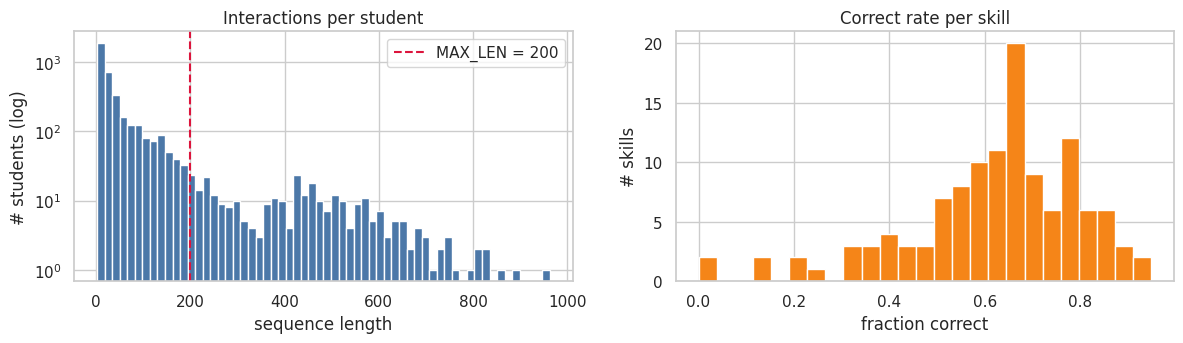

In [5]:
# Map problem_id to question_idx using the saved question_to_idx dictionary
data["question_idx"] = data["problem_id"].astype(str).map(question_to_idx)

seq_lens = data.groupby("user_id").size()
skill_rate = data[["correct", "skill_ids"]].explode("skill_ids").groupby("skill_ids")["correct"].mean()
overall_rate = data["correct"].mean()

print(f"Overall correct rate           : {overall_rate:.3f}  (always-guess-majority accuracy = {max(overall_rate, 1 - overall_rate):.3f})")
print(f"Interactions per student       : median {seq_lens.median():.0f} | 95th pct {seq_lens.quantile(0.95):.0f} | max {seq_lens.max():,}")
print(f"Students longer than MAX_LEN   : {(seq_lens > MAX_LEN).mean():.1%}  (these get cut into several windows)")
q_counts = data["question_idx"].value_counts()
print(f"Attempts per question          : median {q_counts.median():.0f} | questions with < 10 attempts: {(q_counts < 10).mean():.1%}  (their learned difficulty will be noisy)")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(seq_lens, bins=60, color="#4c78a8")
ax[0].set_yscale("log")
ax[0].axvline(MAX_LEN, color="crimson", ls="--", label=f"MAX_LEN = {MAX_LEN}")
ax[0].set(title="Interactions per student", xlabel="sequence length", ylabel="# students (log)")
ax[0].legend()
ax[1].hist(skill_rate, bins=25, color="#f58518")
ax[1].set(title="Correct rate per skill", xlabel="fraction correct", ylabel="# skills")
plt.tight_layout()
plt.show()

## 4. Splits and sequence windows

**Split by student.** If we split random *interactions*, the same student would appear in both train and test, and a model could score well just by memorising that student's habits. Splitting by student tests the thing we actually care about: *does the model generalise to people it has never seen?*

We use **80% train / 10% validation / 10% test** of students:
- **train**: fit the weights,
- **validation**: choose which epoch to keep (and spot overfitting),
- **test**: touched exactly once per model, at the very end.

**Windowing.** Students have wildly different history lengths. We cut each student's history into consecutive windows of at most `MAX_LEN = 200` interactions so batches are manageable. Two honest caveats: a window starts "cold" (it can't see earlier windows), and the first step of each window is never predicted because there's nothing before it.

In [6]:
# Build each student's (skills, correctness) arrays once, then slice into windows per split.
# skills are a (steps, K) matrix here: every step carries ALL skills of its problem.
user_seqs = {
    uid: (skill_mat[g.index.to_numpy()], g["correct"].to_numpy(), g["question_idx"].to_numpy())
    for uid, g in data.groupby("user_id", sort=False)
}

def make_chunks(user_ids):
    chunks = []
    for uid in user_ids:
        s, c, q = user_seqs[uid]
        for i in range(0, len(s), MAX_LEN):
            s_ch, c_ch, q_ch = s[i:i + MAX_LEN], c[i:i + MAX_LEN], q[i:i + MAX_LEN]
            if len(s_ch) >= MIN_SEQ_LEN:
                chunks.append((s_ch, c_ch, q_ch))
    return chunks

rng = np.random.default_rng(SEED)
students = rng.permutation(data["user_id"].unique())
n_tr = int(SPLIT[0] * len(students))
n_va = int(SPLIT[1] * len(students))
train_ids, val_ids, test_ids = students[:n_tr], students[n_tr:n_tr + n_va], students[n_tr + n_va:]

# Safety check: no student may appear in two splits.
assert not (set(train_ids) & set(val_ids)) and not (set(train_ids) & set(test_ids)) and not (set(val_ids) & set(test_ids))

train_chunks, val_chunks, test_chunks = map(make_chunks, (train_ids, val_ids, test_ids))

summary = pd.DataFrame({
    "split": ["train", "val", "test"],
    "students": [len(train_ids), len(val_ids), len(test_ids)],
    "windows": [len(train_chunks), len(val_chunks), len(test_chunks)],
    "predictions": [sum(len(w[0]) - 1 for w in ch) for ch in (train_chunks, val_chunks, test_chunks)],
})
display(summary.style.format({"students": "{:,}", "windows": "{:,}", "predictions": "{:,}"}).hide(axis="index"))

split,students,windows,predictions
train,"3,217","3,629","204,880"
val,402,457,"25,533"
test,403,448,"24,309"


## 5. Batching: shifting by one step, and what each tensor means

Predicting step $t+1$ from steps $\le t$ means **inputs and targets are the same sequence shifted by one**. For a window of length $L$ we build six aligned tensors of length $L-1$:

| Tensor | Definition | Role |
|---|---|---|
| `ex` | skills $s_1..s_{L-1}$ | the skill of each past exercise |
| `ans` | $s_t + N\cdot c_t$ for $t=1..L-1$ | the past *interactions* (skill + outcome) |
| `target` | skills $s_2..s_L$ | the skill of the exercise we must predict |
| `y` | correctness $c_2..c_L$ | the label |
| `ex_q` | question IDs of steps $1..L-1$ | *which exact question* each past interaction was (used by the question-aware models: AKT (with Rasch), simpleKT, AT-DKT, QIKT) |
| `tgt_q` | question IDs of steps $2..L$ | which exact question we must predict (used by the question-aware models: AKT (with Rasch), simpleKT, AT-DKT, QIKT) |

**Worked example** with $N=3$ skills and a tiny history: skills `[2, 0, 2, 1]`, correct `[1, 0, 0, 1]`.

| position | `ex` | `ans` = skill + 3·correct | `target` | `y` |
|---|---|---|---|---|
| 0 | 2 | 2 + 3·1 = **5** | 0 | 0 |
| 1 | 0 | 0 + 3·0 = **0** | 2 | 0 |
| 2 | 2 | 2 + 3·0 = **2** | 1 | 1 |

Read row 0 as: *"after the student got skill 2 right, will they get skill 0 right? (they didn't, y = 0)"*.

Windows in a batch have different lengths, so we right-pad: skill tokens with `PAD_SKILL = N`, interaction tokens with `PAD_INTER = 2N`, and keep a boolean **`mask`** that is `True` on real steps. Loss and metrics use only masked-in positions.

**One collate function serves all models.** DKT's input is exactly `ans`, and its "which skill to read out" is `target`. The old notebook had two separate collators and six near-identical copies of the training loop.

**Multi-skill update.** A step can carry several skills, so `ex`, `ans` and `target` are now `(batch, steps, K)`: up to `K` skill slots per step, padded with `PAD_SKILL` / `PAD_INTER`. The token for slot $j$ is still $s_{t,j} + N\cdot c_t$ (every skill of one problem shares that problem's correctness). `y`, `mask`, `ex_q`, `tgt_q` stay `(batch, steps)`. Each model **mean-pools** the embeddings of the real (non-pad) slots into one vector per step, so a 3-skill problem contributes all 3 skills but is still ONE step with ONE label.

In [7]:
def collate(batch):
    ex, ans, tgt, y, m, exq, tgq = [], [], [], [], [], [], []
    for s, c, q in batch:
        s = s.astype(np.int64)
        c = c.astype(np.int64)
        q = q.astype(np.int64)
        exq.append(torch.as_tensor(q[:-1]))
        tgq.append(torch.as_tensor(q[1:]))
        ex.append(torch.as_tensor(s[:-1]))                                        # (L-1, K)
        # token = skill + N*correct for real slots, PAD_INTER for padded slots
        ans.append(torch.as_tensor(np.where(s[:-1] == PAD_SKILL, PAD_INTER, s[:-1] + N * c[:-1, None])))
        tgt.append(torch.as_tensor(s[1:]))
        y.append(torch.as_tensor(c[1:]).float())
        m.append(torch.ones(len(s) - 1, dtype=torch.bool))
    return (
        pad_sequence(ex,  batch_first=True, padding_value=PAD_SKILL),
        pad_sequence(ans, batch_first=True, padding_value=PAD_INTER),
        pad_sequence(tgt, batch_first=True, padding_value=PAD_SKILL),
        pad_sequence(y,   batch_first=True, padding_value=0.0),
        pad_sequence(m,   batch_first=True, padding_value=False),
        pad_sequence(exq, batch_first=True, padding_value=PAD_QUESTION),
        pad_sequence(tgq, batch_first=True, padding_value=PAD_QUESTION),
    )


def make_loader(chunks, train):
    # A fresh, seeded generator means every model sees the same shuffled batch order.
    g = torch.Generator().manual_seed(SEED)
    return DataLoader(chunks, batch_size=BATCH_TRAIN if train else BATCH_EVAL,
                      shuffle=train, collate_fn=collate, generator=g if train else None)


# Sanity check on real data: decode the first few steps of one window.
ex, ans, tgt, y, mask, ex_q, tgt_q = collate(train_chunks[:2])
print("batch shapes:", {k: tuple(v.shape) for k, v in zip(["ex", "ans", "target", "y", "mask", "ex_q", "tgt_q"], [ex, ans, tgt, y, mask, ex_q, tgt_q])})

s0, c0, q0 = train_chunks[0]
k = min(6, len(s0) - 1)
real = lambda rows, pad: [[int(v) for v in row if v != pad] for row in rows]     # hide padded slots
display(pd.DataFrame({
    "t": range(1, k + 1),
    "skills s_t": real(s0[:k], PAD_SKILL),
    "question": q0[:k],
    "correct c_t": c0[:k],
    "ans = s + N*c_t (per skill)": real(ans[0, :k].tolist(), PAD_INTER),
    "target (next skills)": real(tgt[0, :k].tolist(), PAD_SKILL),
    "y (next correct)": y[0, :k].int().tolist(),
}).style.hide(axis="index"))

batch shapes: {'ex': (2, 8, 4), 'ans': (2, 8, 4), 'target': (2, 8, 4), 'y': (2, 8), 'mask': (2, 8), 'ex_q': (2, 8), 'tgt_q': (2, 8)}


t,skills s_t,question,correct c_t,ans = s + N*c_t (per skill),target (next skills),y (next correct)
1,[119],1897,0,[119],[119],0
2,[119],2578,0,[119],[119],0
3,[119],1922,0,[119],[119],0
4,[119],1851,0,[119],[119],0


## 6. Model definitions

All models share one call signature, `model(ex, ans, target, mask, ex_q, tgt_q) -> logits` of shape `(batch, steps)`, so the same training code runs all of them. (Each model simply ignores the inputs it doesn't need; AKT (with Rasch), simpleKT, AT-DKT and QIKT also read the question IDs.)

### DKT: a recurrent network with a running "knowledge state"
Embed each interaction token, feed the sequence through an LSTM, and at every step output one logit **per skill** (how likely is the student to get *each* skill right next?). We read out the logit for the skill that actually comes next. This is the embedding-input variant of DKT (the original paper one-hot encodes the input).

**Three flavours of the recurrent cell** (the only thing that changes between the DKT variants):
- **Plain RNN:** rewrites one summary note after every answer. Simple, but on long histories early details get overwritten and training struggles to pass learning signal back that far (the vanishing-gradient problem).
- **LSTM:** adds *gates* that decide what to keep and what to forget, so important information (e.g. "keeps failing ratios") survives longer.
- **GRU:** a lighter cousin of the LSTM with fewer gates. Often matches it while being a bit faster.

### SAKT: look back with self-attention
No recurrent state. To predict step $t+1$, the **query** is the upcoming exercise's skill, and the **keys/values** are all past interactions. Attention weights say "which past interactions are relevant to this question?" (e.g. earlier attempts at the *same* skill). A causal mask stops position $t$ from seeing anything after $t$.

The `use_positions` switch adds a learned **positional embedding**. Without it, attention is blind to *when* things happened, since only the content of past interactions matters, not their order.

> **A note on padding masks.** The original notebook pitched a padding mask as an "improvement". With right-padding plus a causal mask, a real step can never attend to a padding position anyway (padding only sits *after* real steps), so the mask doesn't change any real prediction. It's kept as a harmless safety net. The meaningful ablation here is **positions on/off**.

### AKT: context-aware attentive knowledge tracing (full model)
Implemented following Ghosh et al. (2020) and the official code.

**1. Rasch embeddings.** Each question gets a scalar difficulty $\mu_q$ (initialised at 0, learned). The skill embedding is nudged by it:

$$x_t = c_{s_t} + \mu_{q_t}\cdot d_{s_t}, \qquad y_t = e_{(s_t,c_t)} + \mu_{q_t}\cdot f_{(s_t,c_t)}$$

where $c_s$ is the skill embedding, $d_s$ its "variation" vector, $e$ the (skill, outcome) embedding and $f$ its variation vector. `use_rasch=False` drops $\mu$ and gives the skill-only variant.

**2. Three attention modules.**
- **Question encoder:** self-attention over $x_1..x_t$ (may see the current question) giving $\hat{x}_t$.
- **Knowledge encoder:** self-attention over $y_1..y_t$ giving context-aware responses $\hat{y}_t$.
- **Knowledge retriever:** query = $\hat{x}_t$, keys = $\hat{x}_{1..t-1}$, values = $\hat{y}_{1..t-1}$. Strictly past, so the label can never leak.

**3. Monotonic attention with context-aware distance.** The score between steps $t$ and $\tau$ is multiplied by $e^{-\theta_h d(t,\tau)}$ with

$$d(t,\tau)=\sqrt{|t-\tau|\cdot\sum_{\tau'>\tau}\gamma_{t,\tau'}}, \qquad \theta_h=\text{softplus}(\vartheta_h)$$

where $\gamma_{t,\tau'}$ are the attention weights. So the decay depends not just on how long ago something happened but on how much *other* relevant practice sits in between. $\theta_h$ is learned per head; the distance itself is not back-propagated (as in the official code).

**4. Output.** Post-LayerNorm residual blocks with feed-forward layers (the question-encoder layer has none, as in the official code), then an MLP on `[retrieved ; raw question embedding]`. Query/key share one projection and there are no positional embeddings. A small L2 penalty on the $\mu_q$ of the questions **in the current batch** (`reg_loss`, 1e-5) is added to the loss, as in the official code.

**How it fits our batches.** Our tensors put the *next* question at each position, so `AKT.forward` rebuilds the paper's layout of length $L+1$ (questions for steps $1..L$, responses for steps $1..L-1$ plus one hidden pad) and drops the first output, which has no history.

> **Caveat.** Questions that appear only in validation/test (or very rarely in training) never get a trained $\mu_q$ and stay at 0 ("average"). The EDA prints how many questions have few attempts.
>
> **Differences from the paper's setup:** smaller default size (`d_model=128`, 8 heads, 1 block) and lr 1e-3 with early stopping, shared by all models here. Numbers will not match the paper exactly (different preprocessing and splits).

In [8]:
def pool_emb(emb, idx, pad):
    """Mean of the embeddings of the REAL skill slots. idx: (..., K) -> (..., d). Pad slots are ignored."""
    valid = (idx != pad).unsqueeze(-1).float()
    return (emb(idx) * valid).sum(-2) / valid.sum(-2).clamp(min=1.0)


class DKT(nn.Module):
    # rnn_type: "lstm" | "gru" | "rnn" -- the ONLY difference between the DKT variants.
    def __init__(self, n_skills, emb_size=64, hidden_size=128, rnn_type="lstm"):
        super().__init__()
        self.n_skills = n_skills
 
        self.emb = nn.Embedding(2 * n_skills + 1, emb_size, padding_idx=2 * n_skills)
        rnn_cls = {"lstm": nn.LSTM, "gru": nn.GRU, "rnn": nn.RNN}[rnn_type]
        self.rnn = rnn_cls(emb_size, hidden_size, batch_first=True)
        self.out = nn.Linear(hidden_size, n_skills)

    def forward(self, ex, ans, target, mask=None, ex_q=None, tgt_q=None):
        h, _ = self.rnn(pool_emb(self.emb, ans, 2 * self.n_skills))   # (B, L, hidden); ans is (B, L, K)
        all_skill_logits = self.out(h)                      # (B, L, N): one logit per skill
        # Padding positions carry target == N (out of range); clamp them, they are masked out of the loss anyway.
        valid = (target != self.n_skills).float()                              # (B, L, K) real target slots
        idx = target.clamp(max=self.n_skills - 1)                              # (B, L, K)
        per_skill = all_skill_logits.gather(2, idx)                            # (B, L, K): logit of each target skill
        return (per_skill * valid).sum(-1) / valid.sum(-1).clamp(min=1.0)      # (B, L): mean over the problem's skills


class SAKT(nn.Module):
    def __init__(self, n_skills, emb_size=64, num_heads=4, dropout=0.2,
                 max_len=MAX_LEN, use_positions=False):
        super().__init__()
        self.item_emb = nn.Embedding(n_skills + 1, emb_size, padding_idx=n_skills)
        self.interaction_emb = nn.Embedding(2 * n_skills + 1, emb_size, padding_idx=2 * n_skills)
        self.pos_emb = nn.Embedding(max_len, emb_size) if use_positions else None
        self.attn = nn.MultiheadAttention(emb_size, num_heads, dropout=dropout, batch_first=True)
        self.ffn = nn.Sequential(
            nn.Linear(emb_size, emb_size), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(emb_size, emb_size),
        )
        self.ln1 = nn.LayerNorm(emb_size)
        self.ln2 = nn.LayerNorm(emb_size)
        self.pred = nn.Linear(emb_size, 1)

    def forward(self, ex, ans, target, mask=None, ex_q=None, tgt_q=None):
        L = ex.size(1)
        causal = torch.triu(torch.ones(L, L, dtype=torch.bool, device=ex.device), diagonal=1)  # True = blocked
        q = pool_emb(self.item_emb, target, self.item_emb.padding_idx)            # query: the exercise (all its skills) we must predict
        kv = pool_emb(self.interaction_emb, ans, self.interaction_emb.padding_idx)  # keys/values: past (skills, outcome) interactions
        if self.pos_emb is not None:
            p = self.pos_emb(torch.arange(L, device=ex.device)).unsqueeze(0)
            q, kv = q + p, kv + p
        key_padding = None if mask is None else ~mask       # True = padding
        a, _ = self.attn(q, kv, kv, attn_mask=causal, key_padding_mask=key_padding, need_weights=False)
        x = self.ln1(q + a)
        return self.pred(self.ln2(x + self.ffn(x))).squeeze(-1)


# ----- Full AKT (Ghosh et al., 2020): see markdown above for the exact ingredients -----
class MonotonicAttention(nn.Module):
    """Multi-head attention with the context-aware exponential decay of AKT."""

    def __init__(self, d_model, n_heads, dropout=0.1, kq_same=True):
        super().__init__()
        assert d_model % n_heads == 0
        self.h, self.dk = n_heads, d_model // n_heads
        self.k_lin = nn.Linear(d_model, d_model)
        self.q_lin = self.k_lin if kq_same else nn.Linear(d_model, d_model)
        self.v_lin = nn.Linear(d_model, d_model)
        self.out_lin = nn.Linear(d_model, d_model)
        self.drop = nn.Dropout(dropout)
        # gamma_h; theta_h = softplus(gamma_h) >= 0 is the per-head decay rate
        self.gammas = nn.Parameter(torch.zeros(n_heads, 1, 1))
        nn.init.xavier_uniform_(self.gammas)

    @property
    def decay(self):
        return F.softplus(self.gammas).view(-1)

    def forward(self, q, k, v, allow_diagonal, zero_pad=False):
        B, L, _ = q.shape
        split = lambda x: x.view(B, L, self.h, self.dk).transpose(1, 2)       # (B, h, L, dk)
        q_, k_, v_ = split(self.q_lin(q)), split(self.k_lin(k)), split(self.v_lin(v))
        scores = torch.matmul(q_, k_.transpose(-1, -2)) / math.sqrt(self.dk)   # (B, h, L, L)

        idx = torch.arange(L, device=q.device)
        i, j = idx.unsqueeze(1), idx.unsqueeze(0)
        allowed = (j <= i) if allow_diagonal else (j < i)                      # causal mask

        with torch.no_grad():                                                  # distance is not back-propagated
            s = torch.softmax(scores.masked_fill(~allowed, -1e32), dim=-1) * allowed
            dist_cum = s.cumsum(dim=-1)                                        # mass up to and incl. tau
            dist_total = s.sum(dim=-1, keepdim=True)
            remaining = dist_total - dist_cum                                  # mass strictly after tau
            dist = (remaining * (i - j).abs().float()).clamp(min=0).sqrt()     # d(t, tau)

        theta = F.softplus(self.gammas)                                        # (h, 1, 1)
        effect = torch.exp(-theta * dist).clamp(1e-5, 1e5)                     # exp(-theta * d)
        scores = (scores * effect).masked_fill(~allowed, -1e32)
        w = torch.softmax(scores, dim=-1)
        if zero_pad:                                                           # first step has no past at all
            w = torch.cat([torch.zeros_like(w[:, :, :1]), w[:, :, 1:]], dim=2)
        w = self.drop(w)
        out = torch.matmul(w, v_).transpose(1, 2).reshape(B, L, -1)
        return self.out_lin(out)


class AKTBlock(nn.Module):
    """Attention + residual + LayerNorm, optionally followed by FFN + residual + LayerNorm."""

    def __init__(self, d_model, d_ff, n_heads, dropout, kq_same, use_ffn):
        super().__init__()
        self.attn = MonotonicAttention(d_model, n_heads, dropout, kq_same)
        self.ln1 = nn.LayerNorm(d_model)
        self.drop1 = nn.Dropout(dropout)
        self.use_ffn = use_ffn
        if use_ffn:
            self.ffn = nn.Sequential(nn.Linear(d_model, d_ff), nn.ReLU(), nn.Dropout(dropout),
                                     nn.Linear(d_ff, d_model))
            self.ln2 = nn.LayerNorm(d_model)
            self.drop2 = nn.Dropout(dropout)

    def forward(self, q, k, v, allow_diagonal, zero_pad=False):
        x = self.ln1(q + self.drop1(self.attn(q, k, v, allow_diagonal, zero_pad)))
        if self.use_ffn:
            x = self.ln2(x + self.drop2(self.ffn(x)))
        return x


class AKT(nn.Module):
    """
    use_rasch=False -> concept-only AKT (no question difficulty), needs only skill ids.
    use_rasch=True  -> full AKT with Rasch question difficulty.
    n_blocks        -> number of (question-encoder, retriever) pairs; knowledge encoder gets n_blocks layers.
    """

    def __init__(self, n_skills, n_questions=0, d_model=128, n_heads=8, d_ff=256, n_blocks=1,
                 dropout=0.1, fc_dim=256, kq_same=True, use_rasch=True, l2=1e-5):
        super().__init__()
        self.n_skills, self.n_questions = n_skills, n_questions
        self.use_rasch, self.l2 = use_rasch, l2

        self.item_emb = nn.Embedding(n_skills + 1, d_model, padding_idx=n_skills)             # c_s
        self.inter_emb = nn.Embedding(2 * n_skills + 1, d_model, padding_idx=2 * n_skills)    # e_(s,c)
        if use_rasch:
            self.item_var = nn.Embedding(n_skills + 1, d_model, padding_idx=n_skills)         # d_s
            self.inter_var = nn.Embedding(2 * n_skills + 1, d_model, padding_idx=2 * n_skills)  # f_(s,c)
            self.difficulty = nn.Embedding(n_questions + 1, 1, padding_idx=n_questions)       # mu_q

        self.know_enc = nn.ModuleList(            # y -> y^        (sees steps <= t)
            [AKTBlock(d_model, d_ff, n_heads, dropout, kq_same, use_ffn=True) for _ in range(n_blocks)])
        self.ques_enc = nn.ModuleList(            # x -> x^        (sees steps <= t, no FFN as in official code)
            [AKTBlock(d_model, d_ff, n_heads, dropout, kq_same, use_ffn=False) for _ in range(n_blocks)])
        self.retriever = nn.ModuleList(           # (x^, x^, y^)   (sees steps <  t)
            [AKTBlock(d_model, d_ff, n_heads, dropout, kq_same, use_ffn=True) for _ in range(n_blocks)])

        self.head = nn.Sequential(
            nn.Linear(2 * d_model, fc_dim), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(fc_dim, fc_dim // 2), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(fc_dim // 2, 1))
        self._reset()
        self._reg = torch.zeros(())          # set by every forward pass (Rasch only)

    def _reset(self):
        for name, p in self.named_parameters():
            if p.dim() > 1 and "gammas" not in name:
                nn.init.xavier_uniform_(p)
        with torch.no_grad():
            for emb in (self.item_emb, self.inter_emb):
                emb.weight[emb.padding_idx].zero_()
            if self.use_rasch:
                self.difficulty.weight.zero_()          # every question starts at "average" difficulty
                for emb in (self.item_var, self.inter_var):
                    emb.weight[emb.padding_idx].zero_()

    @property
    def decay(self):
        """Learned theta per head, all attention layers concatenated (notebook prints .mean())."""
        mods = [b.attn for b in (*self.know_enc, *self.ques_enc, *self.retriever)]
        return torch.cat([m.decay for m in mods])

    def reg_loss(self):
        """L2 penalty on the Rasch difficulties of the questions in the LAST forward batch
        (official AKT: 1e-5 * sum(mu^2) over the batch). Add to the BCE loss."""
        if not self.use_rasch:
            return torch.zeros((), device=self.item_emb.weight.device)
        return self._reg

    def forward(self, ex, ans, target, mask=None, ex_q=None, tgt_q=None):
        # Notebook layout: position i holds past step i (ex, ans) and the NEXT step's question (target).
        # Rebuild the official AKT layout of length T = L+1 (steps 1..L):
        #   questions : [ex_0, target_0, ..., target_{L-1}]       (step 1, then steps 2..L)
        #   responses : [ans_0, ..., ans_{L-1}, <pad>]            (response of step L is the label -> hidden)
        B, L = ex.shape[:2]
        pad_inter = 2 * self.n_skills
        s_full = torch.cat([ex[:, :1], target], dim=1)                                     # (B, L+1, K)
        a_full = torch.cat([ans, torch.full((B, 1, ans.size(-1)), pad_inter, dtype=ans.dtype, device=ans.device)], dim=1)

        x = pool_emb(self.item_emb, s_full, self.n_skills)                                 # mean over the step's skills
        y = pool_emb(self.inter_emb, a_full, pad_inter)
        if self.use_rasch:
            q_full = torch.cat([ex_q[:, :1], tgt_q], dim=1)
            mu = self.difficulty(q_full)                                                   # (B, L+1, 1)
            self._reg = self.l2 * (mu ** 2).sum()                                          # batch-only, as in the official code
            x = x + mu * pool_emb(self.item_var, s_full, self.n_skills)                    # x_t = c_s + mu_q d_s
            y = y + mu * pool_emb(self.inter_var, a_full, pad_inter)                       # y_t = e_(s,c) + mu_q f_(s,c)
        x_raw = x

        for blk in self.know_enc:                                                          # knowledge encoder
            y = blk(y, y, y, allow_diagonal=True)
        for q_blk, r_blk in zip(self.ques_enc, self.retriever):
            x = q_blk(x, x, x, allow_diagonal=True)                                        # question encoder
            x = r_blk(x, x, y, allow_diagonal=False, zero_pad=True)                        # knowledge retriever

        h = torch.cat([x, x_raw], dim=-1)[:, 1:]                                           # drop step 1 (no history)
        return self.head(h).squeeze(-1)                                                    # (B, L)

### Three more question-aware models: simpleKT, AT-DKT, QIKT

These three all use the **question ID** as well as the skills, so on their own they are not a like-for-like comparison with DKT, SAKT or AKT (no Rasch). The fair pairings are with **AKT (with Rasch)**, which also sees questions. All three keep the notebook's call signature, and the multi-skill handling is unchanged (mean-pooled skill embeddings, one step per problem attempt).

**simpleKT** (after Liu et al., 2023). Each question gets a Rasch-style embedding $x_t = c_{s_t} + \mu_{q_t}\, d_{s_t}$, and each past interaction is $y_t = x_t + e_{r_t}$ with a response embedding $e_r$. A small stack of ordinary transformer blocks then uses the **next** question as the query, past question embeddings as keys and past interactions as values, with learned positional embeddings and a causal mask. The output MLP reads `[attended state ; next-question embedding]`. There is no context-aware decay, so it is the "simple" counterpart to AKT.

**AT-DKT, AT-DKT-style** (after Liu et al., 2023). A DKT LSTM whose input adds a question-and-outcome embedding, and whose output adds a per-question readout to the usual per-skill readout. Two auxiliary losses are added **during training only**:
- *Question tagging:* from the hidden state, predict the skills of the next problem (a soft multi-label cross-entropy, so multi-skill problems work).
- *Individualised prior knowledge:* from the hidden state, predict the student's overall accuracy over the window.

The auxiliary heads are never used to make a prediction, so nothing from the future reaches validation or test. They only shape the hidden state. Their weights (`w_qt`, `w_ik`, both 0.1) are untuned.

**QIKT, simplified** (after Chen et al., 2023). The LSTM input is question-centric: question embedding + pooled skill embedding + response embedding. Two heads then predict the next step: a **question-level IRT-style head** (a scalar ability from the state, plus a question-state interaction, minus a learned question difficulty) and a **skill-level head** (the DKT-style per-skill readout). The final logit is $\lambda_q\,\text{logit}_q + (1-\lambda_q)\,\text{logit}_c$.

> **Differences from the papers.** This is a compact re-implementation inside the shared training loop, so numbers will not match the papers. In particular, the original QIKT trains its two heads with separate losses and splits the IRT head into knowledge-acquisition and problem-solving parts, which this version does not. AT-DKT's auxiliary targets follow the paper's idea but not its exact code. **DTransformer** (contrastive learning with data augmentation and multi-stream knowledge parameters) is **not** re-implemented here, because it needs its own training procedure; it is not included in this notebook.

In [9]:
def decode_correct(ans, n_skills):
    """Recover each step's correctness (0/1, float) from the interaction tokens.
    ans: (B, L, K) with token = skill + N*correct on real slots and 2N on padded slots.
    Slot 0 is always a real skill on real steps, so it carries the correctness.
    (On batch-padding positions the value is meaningless, but those are masked out everywhere.)"""
    return (ans[..., 0] >= n_skills).float()                         # (B, L)


def skill_readout(all_logits, target, n_skills):
    """DKT-style read-out: pick each target skill's logit and average over the problem's real skills."""
    valid = (target != n_skills).float()                                   # (B, L, K)
    per_skill = all_logits.gather(2, target.clamp(max=n_skills - 1))       # (B, L, K)
    return (per_skill * valid).sum(-1) / valid.sum(-1).clamp(min=1.0)      # (B, L)


# ----- simpleKT -----
class SimpleKTBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout):
        super().__init__()
        self.attn = nn.MultiheadAttention(d_model, n_heads, dropout=dropout, batch_first=True)
        self.ln1, self.ln2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(nn.Linear(d_model, d_ff), nn.ReLU(), nn.Dropout(dropout), nn.Linear(d_ff, d_model))
        self.drop = nn.Dropout(dropout)

    def forward(self, q, k, v, causal):
        a, _ = self.attn(q, k, v, attn_mask=causal, need_weights=False)
        x = self.ln1(q + self.drop(a))
        return self.ln2(x + self.drop(self.ffn(x)))


class SimpleKT(nn.Module):
    def __init__(self, n_skills, n_questions, d_model=128, n_heads=8, d_ff=256, n_blocks=2,
                 dropout=0.2, fc_dim=256, max_len=MAX_LEN, l2=1e-5):
        super().__init__()
        self.n_skills, self.n_questions, self.l2 = n_skills, n_questions, l2
        self.item_emb = nn.Embedding(n_skills + 1, d_model, padding_idx=n_skills)      # c_s
        self.item_var = nn.Embedding(n_skills + 1, d_model, padding_idx=n_skills)      # d_s
        self.difficulty = nn.Embedding(n_questions + 1, 1, padding_idx=n_questions)    # mu_q
        self.resp_emb = nn.Embedding(2, d_model)                                       # e_r
        self.pos_emb = nn.Embedding(max_len, d_model)
        self.blocks = nn.ModuleList([SimpleKTBlock(d_model, n_heads, d_ff, dropout) for _ in range(n_blocks)])
        self.head = nn.Sequential(
            nn.Linear(2 * d_model, fc_dim), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(fc_dim, fc_dim // 2), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(fc_dim // 2, 1))
        with torch.no_grad():
            self.difficulty.weight.zero_()                     # every question starts at "average" difficulty
            self.item_var.weight[n_skills].zero_()
        self._reg = torch.zeros(())                            # set by every forward pass

    def _question_emb(self, skills, q):
        mu = self.difficulty(q)                                                         # (B, L, 1)
        return pool_emb(self.item_emb, skills, self.n_skills) + mu * pool_emb(self.item_var, skills, self.n_skills)

    def reg_loss(self):
        """L2 penalty on the difficulties of the questions in the LAST forward batch (not on all questions)."""
        return self._reg

    def forward(self, ex, ans, target, mask=None, ex_q=None, tgt_q=None):
        L = ex.size(1)
        causal = torch.triu(torch.ones(L, L, dtype=torch.bool, device=ex.device), diagonal=1)   # True = blocked
        self._reg = self.l2 * (self.difficulty(tgt_q) ** 2).sum()
        r = decode_correct(ans, self.n_skills).long()
        pos = self.pos_emb(torch.arange(L, device=ex.device)).unsqueeze(0)
        x_past = self._question_emb(ex, ex_q)                      # past questions   (keys)
        y_past = x_past + self.resp_emb(r)                         # past interactions (values)
        x_next = self._question_emb(target, tgt_q)                 # question to predict (query)
        k, v, h = x_past + pos, y_past + pos, x_next + pos
        for blk in self.blocks:
            h = blk(h, k, v, causal)
        return self.head(torch.cat([h, x_next], dim=-1)).squeeze(-1)


# ----- AT-DKT (AT-DKT-style) -----
class ATDKT(nn.Module):
    def __init__(self, n_skills, n_questions, emb_size=64, hidden_size=128, dropout=0.2, w_qt=0.1, w_ik=0.1):
        super().__init__()
        self.n_skills, self.n_questions, self.w_qt, self.w_ik = n_skills, n_questions, w_qt, w_ik
        self.emb = nn.Embedding(2 * n_skills + 1, emb_size, padding_idx=2 * n_skills)             # (skill, outcome)
        self.q_inter = nn.Embedding(2 * n_questions + 1, emb_size, padding_idx=2 * n_questions)   # (question, outcome)
        self.rnn = nn.LSTM(emb_size, hidden_size, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.skill_out = nn.Linear(hidden_size, n_skills)                  # per-skill read-out
        self.q_out = nn.Embedding(n_questions + 1, hidden_size, padding_idx=n_questions)   # per-question read-out (row of a Linear)
        self.q_bias = nn.Embedding(n_questions + 1, 1, padding_idx=n_questions)
        self.qt_head = nn.Linear(hidden_size, n_skills)                    # aux: skills of the next problem
        self.ik_head = nn.Linear(hidden_size, 1)                           # aux: student's overall accuracy
        with torch.no_grad():
            nn.init.normal_(self.q_out.weight, std=0.05)
            self.q_out.weight[n_questions].zero_()
            self.q_bias.weight.zero_()
        self._aux = torch.zeros(())

    def reg_loss(self):
        """Auxiliary losses of the LAST forward pass (zero in eval). The training loop adds this to the BCE."""
        return self._aux

    def forward(self, ex, ans, target, mask=None, ex_q=None, tgt_q=None):
        N, Q = self.n_skills, self.n_questions
        B, L = ex.shape[:2]
        r = decode_correct(ans, N)                                                         # (B, L) float
        q_tok = torch.where(ex_q == Q, torch.full_like(ex_q, 2 * Q), ex_q + Q * r.long())
        h, _ = self.rnn(pool_emb(self.emb, ans, 2 * N) + self.q_inter(q_tok))
        h = self.drop(h)
        logits = skill_readout(self.skill_out(h), target, N) \
                 + (h * self.q_out(tgt_q)).sum(-1) + self.q_bias(tgt_q).squeeze(-1)

        if self.training:                                       # auxiliary losses: training only, never used to predict
            m = torch.ones_like(r) if mask is None else mask.float()
            denom = m.sum().clamp(min=1.0)
            hot = torch.zeros(B, L, N + 1, device=h.device).scatter_(2, target, 1.0)[..., :N]
            hot = hot / hot.sum(-1, keepdim=True).clamp(min=1.0)                           # soft multi-skill target
            qt = -(hot * F.log_softmax(self.qt_head(h), dim=-1)).sum(-1)
            qt = (qt * m).sum() / denom
            # At timestep t, h_t has seen answers through t only. Use the
            # cumulative accuracy of that observed prefix, never the full-window
            # accuracy (which would leak later answers into earlier auxiliary targets).
            m_float = m.to(r.dtype)
            hist_n = m_float.cumsum(dim=1).clamp(min=1.0)
            hist_acc = (r * m_float).cumsum(dim=1) / hist_n
            ik_pred = torch.sigmoid(self.ik_head(h)).squeeze(-1)
            ik = (((ik_pred - hist_acc) ** 2) * m_float).sum() / denom
            self._aux = self.w_qt * qt + self.w_ik * ik
        else:
            self._aux = torch.zeros((), device=h.device)
        return logits


# ----- QIKT (simplified) -----
class QIKT(nn.Module):
    def __init__(self, n_skills, n_questions, emb_size=64, hidden_size=128, dropout=0.2, lam_q=0.5):
        super().__init__()
        self.n_skills, self.n_questions, self.lam_q, self.emb_size = n_skills, n_questions, lam_q, emb_size
        self.skill_emb = nn.Embedding(n_skills + 1, emb_size, padding_idx=n_skills)
        self.q_emb = nn.Embedding(n_questions + 1, emb_size, padding_idx=n_questions)
        self.resp_emb = nn.Embedding(2, emb_size)
        self.rnn = nn.LSTM(emb_size, hidden_size, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.q_ability = nn.Linear(hidden_size, 1)                 # question-level (IRT-style) head
        self.q_proj = nn.Linear(hidden_size, emb_size)
        self.q_diff = nn.Embedding(n_questions + 1, 1, padding_idx=n_questions)
        self.skill_out = nn.Linear(hidden_size, n_skills)          # skill-level head
        with torch.no_grad():
            self.q_diff.weight.zero_()

    def forward(self, ex, ans, target, mask=None, ex_q=None, tgt_q=None):
        N = self.n_skills
        r = decode_correct(ans, N).long()
        u = self.q_emb(ex_q) + pool_emb(self.skill_emb, ex, N) + self.resp_emb(r)   # question-centric interaction
        h, _ = self.rnn(u)
        h = self.drop(h)
        logit_q = (self.q_ability(h).squeeze(-1)
                   + (self.q_proj(h) * self.q_emb(tgt_q)).sum(-1) / math.sqrt(self.emb_size)
                   - self.q_diff(tgt_q).squeeze(-1))
        logit_c = skill_readout(self.skill_out(h), target, N)
        return self.lam_q * logit_q + (1 - self.lam_q) * logit_c

In [10]:
def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

MODEL_ZOO = {
    "DKT (LSTM)":       lambda: DKT(N, rnn_type="lstm"),
    "DKT (GRU)":        lambda: DKT(N, rnn_type="gru"),
    "DKT (RNN)":        lambda: DKT(N, rnn_type="rnn"),
    "SAKT":             lambda: SAKT(N, use_positions=False),
    "SAKT + positions": lambda: SAKT(N, use_positions=True),
    "AKT (no Rasch)":   lambda: AKT(N, use_rasch=False),
    "AKT":              lambda: AKT(N, n_questions=Q, use_rasch=True),
    "simpleKT":         lambda: SimpleKT(N, Q),
    "AT-DKT":           lambda: ATDKT(N, Q),
    "QIKT (simplified)": lambda: QIKT(N, Q),
}
for name, build in MODEL_ZOO.items():
    print(f"{name:<18} {count_params(build()):>10,} trainable parameters")

DKT (LSTM)            131,003 trainable parameters
DKT (GRU)             106,171 trainable parameters
DKT (RNN)              56,507 trainable parameters
SAKT                   49,025 trainable parameters
SAKT + positions       61,825 trainable parameters
AKT (no Rasch)        428,057 trainable parameters
AKT                   491,468 trainable parameters
simpleKT              437,300 trainable parameters
AT-DKT              4,239,146 trainable parameters
QIKT (simplified)   1,166,639 trainable parameters


## 7. Training engine

One `fit()` function trains any model from the zoo:

- **Loss:** `BCEWithLogitsLoss` computed only on real (`mask == True`) steps.
- **Optimiser:** Adam, `lr = 1e-3`; gradient norm clipped at 5 (keeps the LSTM stable).
- **Model selection:** after each epoch, compute **validation AUC**; keep a copy of the weights from the best epoch and restore them at the end. So the test set is evaluated with the *best-validation* model, not whichever epoch happened to be last. The same rule picks the best *model* of the whole zoo: it is the one with the highest validation AUC, and its weights are written to disk before the test set is touched.
- **Fairness:** `set_seed()` before each model, and the training loader reuses the same seeded shuffle, so all models see identical batches in identical order.

In [11]:
loss_fn = nn.BCEWithLogitsLoss()


def to_device(batch):
    return [t.to(device) for t in batch]


def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss, total_steps = 0.0, 0
    for batch in loader:
        ex, ans, tgt, y, mask, ex_q, tgt_q = to_device(batch)
        logits = model(ex, ans, tgt, mask, ex_q, tgt_q)
        loss = loss_fn(logits[mask], y[mask])
        if hasattr(model, "reg_loss"):
            loss = loss + model.reg_loss()      # AKT: L2 on Rasch difficulties (zero for other models)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        optimizer.step()
        n = int(mask.sum())
        total_loss += loss.item() * n
        total_steps += n
    return total_loss / total_steps


@torch.no_grad()
def predict(model, loader):
    # Returns flat (labels, probabilities) over all real prediction steps.
    model.eval()
    labels, probs = [], []
    for batch in loader:
        ex, ans, tgt, y, mask, ex_q, tgt_q = to_device(batch)
        p = torch.sigmoid(model(ex, ans, tgt, mask, ex_q, tgt_q))
        labels.append(y[mask].cpu().numpy())
        probs.append(p[mask].cpu().numpy())
    return np.concatenate(labels), np.concatenate(probs)


def fit(name, model, train_loader, val_loader, epochs=EPOCHS):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    history = {"train_loss": [], "val_auc": []}
    best_auc, best_epoch, best_state = -1.0, 0, None

    for epoch in range(1, epochs + 1):
        t0 = time.time()
        loss = train_one_epoch(model, train_loader, optimizer)
        yv, pv = predict(model, val_loader)
        auc = roc_auc_score(yv, pv)
        history["train_loss"].append(loss)
        history["val_auc"].append(auc)
        if auc > best_auc:
            best_auc, best_epoch = auc, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(f"{name:<18} epoch {epoch:2d}/{epochs} | train loss {loss:.4f} | val AUC {auc:.4f} | {time.time() - t0:5.1f}s")
        if epoch - best_epoch >= PATIENCE:
            print(f"{name:<18} early stop: no val-AUC gain for {PATIENCE} epochs")
            break

    model.load_state_dict(best_state)   # restore best-validation weights
    return history, best_epoch, best_auc

## 8. Run all experiments

The run has two phases, in this order:

1. **Train and select (validation only).** Every model is trained with early model-selection on validation. The best model of the zoo is the one with the **highest validation AUC**, and its best-validation weights are **saved to `best_model/best_weights.pt` before any test data is scored.**
2. **Test.** Only now is the **test** set scored, once per model, with the restored best-validation weights (the best model is reloaded from the saved file). Test predictions are stored so the plots below don't have to re-run anything.


In [12]:
val_loader = make_loader(val_chunks, train=False)
test_loader = make_loader(test_chunks, train=False)

best_dir = os.path.join(SCRATCH_OUT, "best_model")
os.makedirs(best_dir, exist_ok=True)
best_weights_path = os.path.join(best_dir, "best_weights.pt")

# ======== PHASE 1: train every model, select the best on VALIDATION only (test set not touched) ========
results = {}
for name, build in MODEL_ZOO.items():
    print(f"\n=== {name} ===")
    set_seed(SEED)                                   # same init seed for every model
    model = build()
    train_loader = make_loader(train_chunks, train=True)   # same batch order for every model
    history, best_epoch, best_val_auc = fit(name, model, train_loader, val_loader)   # fit() restores the best-validation epoch

    results[name] = {
        "history": history, "best_epoch": best_epoch, "val_auc": best_val_auc,
        "n_params": count_params(model),
        "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
    }
    if isinstance(model, AKT):
        print(f"learned decay theta = {model.decay.mean().item():.4f} (mean over all heads/layers; theta = softplus(gamma))")
    print(f"-> best epoch {best_epoch} | val AUC {best_val_auc:.4f}")

# ---- pick the best model by validation AUC and SAVE ITS WEIGHTS BEFORE ANY TESTING ----
best_name = max(results, key=lambda n: results[n]["val_auc"])
torch.save(results[best_name]["state"], best_weights_path)
info = {"dataset": DATASET, "model": best_name, "test_auc": None,          # test_auc is filled in after testing (section 9 export cell)
        "val_auc": float(results[best_name]["val_auc"]), "best_epoch": int(results[best_name]["best_epoch"]),
        "n_params": int(results[best_name]["n_params"]),
        "n_skills": int(N), "n_questions": int(Q), "max_skills_per_step": int(K), "max_len": int(MAX_LEN),
        "padding_indices": {"skill": int(PAD_SKILL), "question": int(PAD_QUESTION)},
        "rebuild": f'model = MODEL_ZOO["{best_name}"]()   # then model.load_state_dict(torch.load("best_weights.pt"))',
        "selection": "highest Val AUC among models trained in this run; selected using validation only and saved before any test evaluation"}
with open(os.path.join(best_dir, "best_model_info.json"), "w") as f:
    json.dump(info, f, indent=2)
print(f"\nBest model by VALIDATION AUC: {best_name} (val AUC {info['val_auc']:.4f}, epoch {info['best_epoch']})")
print(f"Weights saved BEFORE testing -> {best_weights_path}")

# ======== PHASE 2: testing (test set scored once per model, with the best-validation weights) ========
print("\n--- Testing ---")
for name, build in MODEL_ZOO.items():
    r = results[name]
    model = build()
    # the winning model is reloaded from the file that was just saved; the others use their in-memory best-validation weights
    model.load_state_dict(torch.load(best_weights_path, map_location="cpu") if name == best_name else r["state"])
    model.to(device)
    y_test, p_test = predict(model, test_loader)
    r["y_test"], r["p_test"] = y_test, p_test
    print(f"{name:<18} best epoch {r['best_epoch']:2d} | val AUC {r['val_auc']:.4f} | TEST AUC {roc_auc_score(y_test, p_test):.4f}")



=== DKT (LSTM) ===
DKT (LSTM)         epoch  1/60 | train loss 0.6104 | val AUC 0.7198 |   3.9s
DKT (LSTM)         epoch  2/60 | train loss 0.5592 | val AUC 0.7375 |   0.8s
DKT (LSTM)         epoch  3/60 | train loss 0.5476 | val AUC 0.7454 |   0.8s
DKT (LSTM)         epoch  4/60 | train loss 0.5404 | val AUC 0.7480 |   0.8s
DKT (LSTM)         epoch  5/60 | train loss 0.5351 | val AUC 0.7519 |   0.8s
DKT (LSTM)         epoch  6/60 | train loss 0.5312 | val AUC 0.7534 |   0.8s
DKT (LSTM)         epoch  7/60 | train loss 0.5273 | val AUC 0.7552 |   0.8s
DKT (LSTM)         epoch  8/60 | train loss 0.5234 | val AUC 0.7550 |   0.7s
DKT (LSTM)         epoch  9/60 | train loss 0.5204 | val AUC 0.7558 |   0.8s
DKT (LSTM)         epoch 10/60 | train loss 0.5174 | val AUC 0.7554 |   0.8s
DKT (LSTM)         epoch 11/60 | train loss 0.5141 | val AUC 0.7556 |   0.8s
DKT (LSTM)         epoch 12/60 | train loss 0.5107 | val AUC 0.7555 |   0.7s
DKT (LSTM)         epoch 13/60 | train loss 0.5076 | val

## 9. Results

**Metrics.** AUC is the headline. Accuracy / precision / recall / F1 use a fixed 0.5 threshold, so they depend on how the model is calibrated and how imbalanced the labels are, which is why the **majority-class baseline** is shown next to them.

In [13]:
def summarise(y, p, threshold=0.5):
    pred = (p >= threshold).astype(int)
    return {
        "Test AUC": roc_auc_score(y, p),
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
    }

rows = []
for name, r in results.items():
    rows.append({"Model": name, "Params": r["n_params"], "Best epoch": r["best_epoch"],
                 "Val AUC": r["val_auc"], **summarise(r["y_test"], r["p_test"])})
results_df = pd.DataFrame(rows)
results_df.assign(dataset=DATASET).to_csv(f"scratch_results_{DATASET}.csv", index=False)   # one file per dataset

y_ref = next(iter(results.values()))["y_test"]       # identical test labels for every model
base_acc = max(y_ref.mean(), 1 - y_ref.mean())

fmt = {"Params": "{:,}", "Val AUC": "{:.4f}", "Test AUC": "{:.4f}", "Accuracy": "{:.4f}",
       "Precision": "{:.4f}", "Recall": "{:.4f}", "F1": "{:.4f}"}
display(results_df.style.format(fmt).hide(axis="index")
        .highlight_max(subset=["Test AUC", "Accuracy", "F1"], color="#cde8cd"))
print(f"Majority-class baseline: accuracy = {base_acc:.4f}, AUC = 0.5000   (n test predictions = {len(y_ref):,})")

Model,Params,Best epoch,Val AUC,Test AUC,Accuracy,Precision,Recall,F1
DKT (LSTM),"131,003",9,0.7558,0.7592,0.7344,0.7568,0.8789,0.8133
DKT (GRU),"106,171",12,0.7577,0.7626,0.7337,0.7533,0.8851,0.8139
DKT (RNN),"56,507",17,0.7514,0.7586,0.7344,0.7533,0.8868,0.8146
SAKT,"49,025",32,0.7409,0.7441,0.7266,0.7403,0.9005,0.8126
SAKT + positions,"61,825",18,0.7239,0.7300,0.7187,0.7374,0.8890,0.8062
AKT (no Rasch),"428,057",16,0.7538,0.7583,0.7339,0.7571,0.8771,0.8127
AKT,"491,468",6,0.7726,0.7774,0.7426,0.7865,0.8357,0.8104
simpleKT,"437,300",5,0.7633,0.7672,0.7358,0.7654,0.8630,0.8113
AT-DKT,"4,239,146",7,0.7614,0.7645,0.7326,0.7676,0.8515,0.8073
QIKT (simplified),"1,166,639",13,0.7655,0.7713,0.7407,0.7668,0.8709,0.8155


Majority-class baseline: accuracy = 0.6581, AUC = 0.5000   (n test predictions = 24,309)


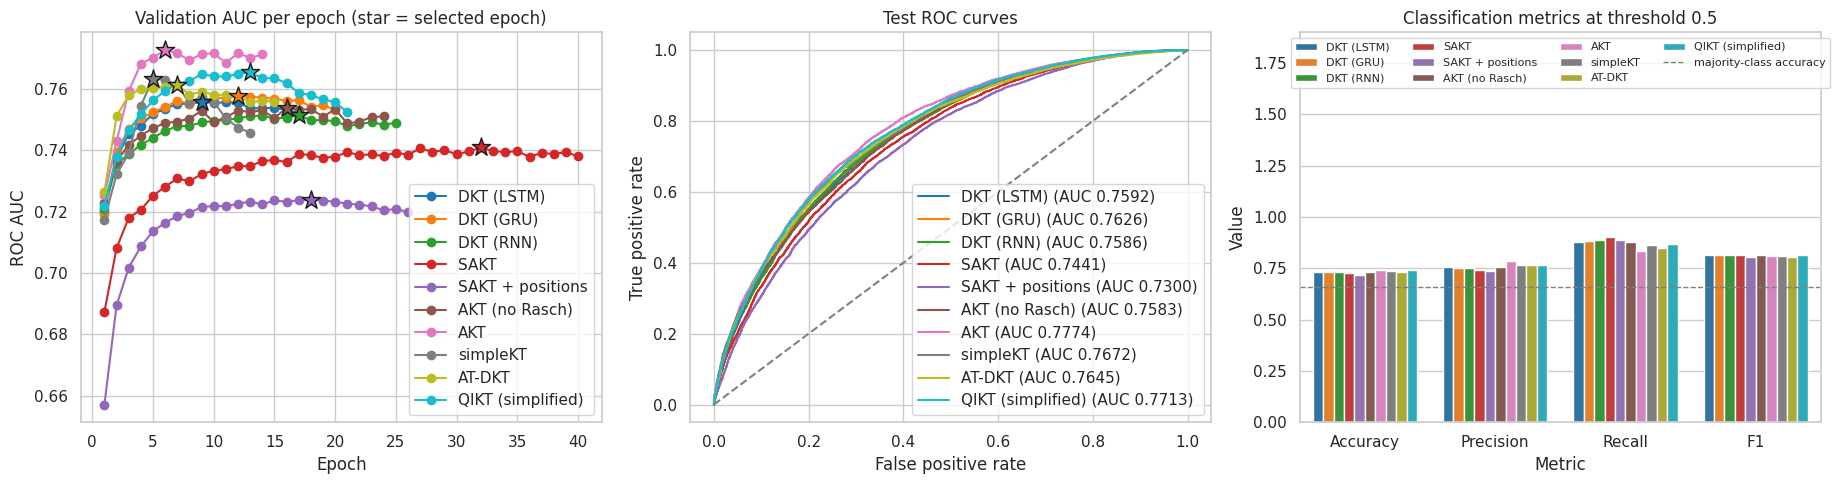

Best test AUC: AKT (0.7774), +0.0061 ahead of QIKT (simplified).


In [14]:
palette = dict(zip(results, sns.color_palette("tab10", len(results))))
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# (1) Validation learning curves, with the selected epoch starred.
for name, r in results.items():
    ep = range(1, len(r["history"]["val_auc"]) + 1)
    axes[0].plot(ep, r["history"]["val_auc"], marker="o", label=name, color=palette[name])
    axes[0].scatter(r["best_epoch"], r["val_auc"], s=190, marker="*", color=palette[name], edgecolor="k", zorder=5)
axes[0].set(title="Validation AUC per epoch (star = selected epoch)", xlabel="Epoch", ylabel="ROC AUC")
axes[0].xaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].legend()

# (2) ROC curves on the held-out test students.
for name, r in results.items():
    fpr, tpr, _ = roc_curve(r["y_test"], r["p_test"])
    axes[1].plot(fpr, tpr, color=palette[name], label=f"{name} (AUC {roc_auc_score(r['y_test'], r['p_test']):.4f})")
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set(title="Test ROC curves", xlabel="False positive rate", ylabel="True positive rate")
axes[1].legend(loc="lower right")

# (3) Threshold-0.5 metrics side by side.
long_df = results_df.melt(id_vars="Model", value_vars=["Accuracy", "Precision", "Recall", "F1"],
                          var_name="Metric", value_name="Value")
sns.barplot(data=long_df, x="Metric", y="Value", hue="Model", palette=palette, ax=axes[2])
axes[2].axhline(base_acc, color="gray", ls="--", lw=1, label="majority-class accuracy")
axes[2].set(title="Classification metrics at threshold 0.5", ylim=(0, 1.9))
axes[2].legend(fontsize=8, loc="upper center", ncol=4)

plt.tight_layout()
plt.show()

ranked = results_df.sort_values("Test AUC", ascending=False).reset_index(drop=True)
gap = ranked.loc[0, "Test AUC"] - ranked.loc[1, "Test AUC"]
print(f"Best test AUC: {ranked.loc[0, 'Model']} ({ranked.loc[0, 'Test AUC']:.4f}), "
      f"{gap:+.4f} ahead of {ranked.loc[1, 'Model']}.")

### Save the best from-scratch model
The best model was chosen in section 8 by **highest validation AUC**, and its best-validation weights were already saved (as a PyTorch `state_dict`) to `best_model/best_weights.pt` **before the test set was scored**. This cell only completes `best_model_info.json` with the test AUC and writes the README. The weights belong with the maps exported above.

To use them, run the model-definition cells of this notebook, rebuild the model with `MODEL_ZOO[name]()` (this needs `N` and `Q` from the same dataset) and call `model.load_state_dict(torch.load(path))`.


In [15]:
# best_name was chosen by validation AUC and best_weights.pt was written in section 8, BEFORE the test set was scored.
best_row = results_df.set_index("Model").loc[best_name]
best_dir = os.path.join(SCRATCH_OUT, "best_model")
assert os.path.exists(os.path.join(best_dir, "best_weights.pt")), "run section 8 first"

info["test_auc"] = float(best_row["Test AUC"])          # recorded after testing; it did not influence the selection
info["selection"] = "highest Val AUC among models trained in this run; selected using validation only and saved before any test evaluation"
with open(os.path.join(best_dir, "best_model_info.json"), "w") as f:
    json.dump(info, f, indent=2)
with open(os.path.join(SCRATCH_OUT, "README.md"), "w") as f:
    f.write(f"""# {DATASET}: from-scratch export

- skill_map.csv / question_map.csv : original id -> mapped_index used by the weights (index {N} / {Q} is padding, not in the map)
- best_model/best_weights.pt       : state_dict of {best_name}, selected by highest validation AUC ({info['val_auc']:.4f}) and saved before testing; test AUC {info['test_auc']:.4f}
- best_model/best_model_info.json  : sizes and how to rebuild the model
""")
print(f"[{DATASET}] best from-scratch model (by validation AUC): {best_name} | val AUC {info['val_auc']:.4f} | test AUC {info['test_auc']:.4f} -> {best_dir}/best_weights.pt")

if SAVE_ALL_WEIGHTS:
    os.makedirs(os.path.join(SCRATCH_OUT, "all_models"), exist_ok=True)
    for name, r in results.items():
        safe = re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_")
        torch.save(r["state"], os.path.join(SCRATCH_OUT, "all_models", f"{safe}.pt"))
    print("also saved every model's weights in", os.path.join(SCRATCH_OUT, "all_models"))


[assist2009] best from-scratch model (by validation AUC): AKT | val AUC 0.7726 | test AUC 0.7774 -> exports/scratch_assist2009/best_model/best_weights.pt


# Milestone 5: Model Evaluation & Analysis (separate testing section)

Everything below only **scores** the selected Milestone 4 checkpoint. No weights are changed, except in the clearly labelled compression experiments (Section M5-9), which work on copies.

**Which model is tested?** By default, the best model trained above (`best_name`, restored with its best-validation weights). To test a checkpoint saved in an earlier run instead, set `CKPT_PATH` in the next cell to its `best_weights.pt` (the `best_model_info.json` must sit next to it). In that case the notebook rebuilds the split with the same seed and stops if the reproduced test AUC differs from the recorded one by more than `REPRO_TOL`, because that would mean the test students are not the original ones.

**Data used.** ASSISTments, the same split the model was trained with: the same cleaned data, `SEED`, 80/10/10 split by student, `MAX_LEN` windows. A different dataset (e.g. Algebra 2005-06) cannot be used for this checkpoint, because the embeddings are tied to this dataset's skill and question ids.

| Requirement | Where |
|---|---|
| 1 Introduction, objectives, scope | M5-1 |
| 2 Held-out set, leakage check, baselines, environment | M5-2 |
| 3 Metrics, justification, FP/FN trade-off | M5-3 |
| 4 Performance, baselines, slices, confidence intervals | M5-4 |
| 5 Error analysis | M5-5 |
| 6 Robustness, within-dataset OOD slices, interpretability, shortcut checks; external OOD explicitly marked not run | M5-6 |
| 7 Limitations, latency, memory, fairness | M5-7 |
| 8 Improvements | M5-8 |
| 9 Deployment readiness, validation-selected compression trade-off | M5-9 |
| 10 Summary and sign-off | M5-10 |

## M5-1. Introduction and objectives

**Checkpoint under test.** The table printed by the next cell lists the model, its size, and the validation/test AUC recorded at training time.

**Objectives of this phase**
1. *Impartial benchmarking:* score the untouched test students once, with decisions (thresholds, calibration) fitted on validation students only, and compare against simple baselines and the other Milestone 4 models.
2. *Error diagnosis:* find where, and why, the model is wrong.
3. *Operational limits:* robustness to bad inputs, latency, memory, fairness proxies, and what can be compressed.

**Scope.** Metrics (M5-3/4), error analysis (M5-5), robustness and interpretability (M5-6), operations and bias (M5-7), then improvements, deployment and sign-off (M5-8 to M5-10). Results tables and figures are written to `exports/eval_outputs/` and are included in the final zip.

> **Selection caveat.** The Milestone 4 checkpoint was chosen by *highest validation AUC* among ten models and saved before testing, so the test set played no part in the choice and the test AUC is an unbiased estimate. (With ten candidates the validation AUC of the winner is mildly optimistic, which is why the test number is the one to report.)

In [16]:
# ===================== M5 configuration, model under test, scoring utilities =====================
import hashlib, platform, io, copy
from sklearn.metrics import brier_score_loss, log_loss, balanced_accuracy_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from scipy.stats import spearmanr
try:
    import psutil
except ImportError:
    psutil = None

M5_OUT = os.path.join(EXPORT_DIR, "eval_outputs"); os.makedirs(M5_OUT, exist_ok=True)
CKPT_PATH = None  # None = evaluate this notebook run's best-validation checkpoint; set a path only for an explicitly documented external checkpoint
BOOT_REPS = 300             # student-level bootstrap resamples
COST_FP, COST_FN = 2.0, 1.0 # FP = predicted "correct" but the student failed (a missed intervention). Costlier, see M5-3
RUN_DISTILLATION, DISTILL_EPOCHS = True, 5
REPRO_TOL = 0.002
# Project-approved acceptance targets were not supplied with the notebook.
# Keep them unset rather than inventing thresholds; populate only with approved targets.
ACCEPTANCE = {"min_test_auc": None, "max_val_test_auc_gap": None, "max_ece": None,
              "min_auc_gain_over_best_baseline": None, "min_directional_pass": None,
              "max_auc_drop_10pct_flipped_history": None, "min_worst_slice_auc": None,
              "max_latency_ms_window200": None}
SUMMARY = {}
def save_table(df, name):
    df.to_csv(os.path.join(M5_OUT, f"{name}.csv"), index=False); return df
def save_fig(name):
    plt.savefig(os.path.join(M5_OUT, f"{name}.png"), dpi=130, bbox_inches="tight")

# ---- which checkpoint ----
if CKPT_PATH:
    w_path = CKPT_PATH
    M5_INFO = json.load(open(os.path.join(os.path.dirname(CKPT_PATH), "best_model_info.json")))
    M5_NAME, state = M5_INFO["model"], torch.load(CKPT_PATH, map_location="cpu")
    assert M5_INFO.get("dataset") == DATASET, f"checkpoint dataset={M5_INFO.get('dataset')} but current DATASET={DATASET}"
    for k, v in [("n_skills", N), ("n_questions", Q), ("max_skills_per_step", K), ("max_len", MAX_LEN)]:
        assert M5_INFO[k] == v, f"checkpoint {k}={M5_INFO[k]} but the rebuilt data gives {v}: wrong data file or cleaning."
else:
    M5_NAME, M5_INFO, state = best_name, dict(info), results[best_name]["state"]
    w_path = os.path.join(best_dir, "best_weights.pt")
model = MODEL_ZOO[M5_NAME](); model.load_state_dict(state); model.to(device).eval()
M5_SHA = hashlib.sha256(open(w_path, "rb").read()).hexdigest() if os.path.exists(w_path) else "n/a"
display(pd.DataFrame({"field": ["model", "trained on", "parameters", "best epoch", "val AUC (recorded)", "test AUC (recorded)",
                                "skills / questions / skills per step / window", "weights sha256 (first 16)"],
                      "value": [M5_NAME, M5_INFO["dataset"], f"{M5_INFO['n_params']:,}", M5_INFO["best_epoch"], f"{M5_INFO['val_auc']:.4f}",
                                f"{M5_INFO['test_auc']:.4f}", f"{N} / {Q} / {K} / {MAX_LEN}", M5_SHA[:16]]}).style.hide(axis="index"))

# ---- scoring utilities ----
@torch.no_grad()
def forward_chunks(m, in_chunks, lab_chunks=None, bs=BATCH_EVAL):
    """Probabilities for every prediction step of `in_chunks`; labels come from `lab_chunks` (default: same chunks).
    Lets us corrupt the INPUT history while keeping the true labels."""
    dev = next(m.parameters()).device; m.eval()
    lab_chunks = in_chunks if lab_chunks is None else lab_chunks
    P, Y = [], []
    for i in range(0, len(in_chunks), bs):
        ex, ans, tgt, _, mask, exq, tgq = [t.to(dev) for t in collate(in_chunks[i:i + bs])]
        y = collate(lab_chunks[i:i + bs])[3].to(dev)
        p = torch.sigmoid(m(ex, ans, tgt, mask, exq, tgq))
        P.append(p[mask].cpu().numpy()); Y.append(y[mask].cpu().numpy())
    return np.concatenate(Y), np.concatenate(P)

@torch.no_grad()
def logits_chunks(m, chunks, bs=128):
    dev = next(m.parameters()).device; m.eval(); out = []
    for i in range(0, len(chunks), bs):
        b = chunks[i:i + bs]; ex, ans, tgt, _, mask, exq, tgq = [t.to(dev) for t in collate(b)]
        lg = m(ex, ans, tgt, mask, exq, tgq).cpu().numpy()
        out += [lg[j, :len(c[1]) - 1] for j, c in enumerate(b)]
    return out

def window_uids(ids):
    out = []
    for uid in ids:
        n = len(user_seqs[uid][0])
        out += [uid] * sum(1 for i in range(0, n, MAX_LEN) if len(range(i, min(i + MAX_LEN, n))) >= MIN_SEQ_LEN)
    return out

def build_meta(chunks, uids):
    cols = {k: [] for k in ["win", "uid", "pos", "skill", "n_sk", "q", "prev_acc", "prev_c", "same_skill", "y"]}
    for j, ((s, c, q), u) in enumerate(zip(chunks, uids)):
        L = len(c); pos = np.arange(1, L)
        cols["win"].append(np.full(L - 1, j)); cols["uid"].append(np.full(L - 1, u)); cols["pos"].append(pos)
        cols["skill"].append(s[1:, 0]); cols["n_sk"].append((s[1:] != PAD_SKILL).sum(1)); cols["q"].append(q[1:])
        cols["prev_acc"].append(np.cumsum(c)[:-1] / pos); cols["prev_c"].append(c[:-1]); cols["same_skill"].append(s[1:, 0] == s[:-1, 0])
        cols["y"].append(c[1:])
    return pd.DataFrame({k: np.concatenate(v) for k, v in cols.items()})

train_uids, test_uids, val_uids = window_uids(train_ids), window_uids(test_ids), window_uids(val_ids)
assert len(train_uids) == len(train_chunks) and len(test_uids) == len(test_chunks) and len(val_uids) == len(val_chunks)
yT, pT = forward_chunks(model, test_chunks); yV, pV = forward_chunks(model, val_chunks)
TR, T, V = build_meta(train_chunks, train_uids), build_meta(test_chunks, test_uids), build_meta(val_chunks, val_uids)
assert len(T) == len(yT) and np.array_equal(T.y.values, yT.astype(int)) and np.array_equal(V.y.values, yV.astype(int))
test_auc_now, val_auc_now = roc_auc_score(yT, pT), roc_auc_score(yV, pV)
print(f"Scored {len(T):,} test predictions ({T.uid.nunique():,} students) and {len(V):,} validation predictions.")

field,value
model,AKT
trained on,assist2009
parameters,"491,468"
best epoch,6
val AUC (recorded),0.7726
test AUC (recorded),0.7774
skills / questions / skills per step / window,123 / 15922 / 4 / 200
weights sha256 (first 16),d86d133eb2e86133


Scored 24,309 test predictions (403 students) and 25,533 validation predictions.


## M5-2. Evaluation setup and test dataset

**Held-out test set.** The split is by student: 80% train / 10% validation / 10% test of students, from `np.random.default_rng(SEED).permutation(...)`. Every window of a test student is a test window, so a student never appears on both sides. The next cell asserts this (students and attempts disjoint) and, as a reproducibility gate, checks that the AUC now equals the one recorded at training time.

**Baselines** (all fitted on training students only, except the logistic combiner, which is fitted on validation students):

| Baseline | What it predicts |
|---|---|
| Majority class | the training correct rate for every step (AUC 0.5) |
| Skill rate | smoothed training correct rate of the skill (mean over the problem's skills) |
| Question rate | smoothed training correct rate of the exact question (falls back to the skill rate) |
| Student running accuracy | the student's accuracy so far, shrunk to the global rate |
| Last-answer repeat | P(correct) given only whether the previous answer was right |
| Logistic combiner | logistic regression on question rate, skill rate, student accuracy, previous answer, history length (a strong non-neural "standard" baseline) |

**Checkpoint and evaluation protocol update.** By default `CKPT_PATH = None`, so this evaluation uses the best-validation checkpoint produced by the current notebook run. External checkpoints must be explicitly configured and must match the dataset and dimensions. Logistic Regression is fitted on training students; thresholds and baseline selection use validation data; test data is reserved for final reporting.


In [17]:
# ---------- leakage checks ----------
tr_s, va_s, te_s = set(train_ids), set(val_ids), set(test_ids)
assert not (tr_s & te_s) and not (va_s & te_s) and not (tr_s & va_s), "a student appears in two splits"
attempts = lambda ids: set(map(tuple, data.loc[data["user_id"].isin(set(ids)), ["user_id", "order_id"]].to_numpy()))
assert not (attempts(train_ids) & attempts(test_ids)) and not (attempts(val_ids) & attempts(test_ids)), "a student-attempt appears in two splits"
assert set(T.uid.unique()) <= te_s
print("Leakage checks passed: students disjoint, attempts disjoint, every test window belongs to a test student.")

# ---------- reproducibility gate ----------
diff = abs(test_auc_now - M5_INFO["test_auc"])
print(f"Recorded test AUC {M5_INFO['test_auc']:.4f} | reproduced now {test_auc_now:.4f} | difference {diff:.4f} (tolerance {REPRO_TOL})")
if diff > REPRO_TOL:
    msg = "Reproduced AUC differs from the recorded one: the test students are NOT the ones the checkpoint was selected on."
    if CKPT_PATH: raise RuntimeError(msg)
    print("WARNING:", msg)
SUMMARY["repro_diff"] = float(diff)

# ---------- test-set characteristics ----------
tr_sk_n, tr_sk_c = np.zeros(N + 1), np.zeros(N + 1); tr_q_n, tr_q_c = np.zeros(Q + 1), np.zeros(Q + 1)
trans = np.zeros((2, 2))                       # trans[prev, cur] counts, for the last-answer baseline
for s, c, q in train_chunks:
    # Count every observed training attempt, including each skill attached to a
    # multi-skill problem and the first step of each window.
    valid_skill = (s != PAD_SKILL)
    skill_labels = np.broadcast_to(c[:, None], s.shape)
    np.add.at(tr_sk_n, s[valid_skill], 1)
    np.add.at(tr_sk_c, s[valid_skill], skill_labels[valid_skill])
    np.add.at(tr_q_n, q, 1); np.add.at(tr_q_c, q, c)
    np.add.at(trans, (c[:-1], c[1:]), 1)
G = float(tr_sk_c.sum() / tr_sk_n.sum())       # global training correct rate

n_test = int(len(T))
n_correct = int((T.y == 1).sum())
n_incorrect = int((T.y == 0).sum())
char = pd.DataFrame({"item": ["test students", "test windows", "test predictions / labelled samples", "correct labels (class 1)", "incorrect labels (class 0)",
                              "correct class proportion", "incorrect class proportion", "questions never seen in training", "questions seen < 5 times in training",
                              "first 5 steps of a window (little history)", "multi-skill problems", "same skill as previous step", "windows shorter than 10 steps"],
                     "value": [int(T.uid.nunique()), int(len(test_chunks)), n_test, n_correct, n_incorrect,
                               n_correct / max(n_test, 1), n_incorrect / max(n_test, 1), (tr_q_n[T.q] == 0).mean(), (tr_q_n[T.q] < 5).mean(),
                               (T.pos < 5).mean(), (T.n_sk > 1).mean(), T.same_skill.mean(), np.mean([len(c[1]) < 10 for c in test_chunks])]})
display(save_table(char, "2_test_set_characteristics").style.format({"value": lambda v: f"{v:,.0f}" if float(v).is_integer() and v >= 1 else f"{v:.3f}"}).hide(axis="index"))
assert n_correct + n_incorrect == n_test, "Test class counts do not sum to the number of labelled predictions."
print(f"Test class distribution: class 1 (correct) = {n_correct:,} ({n_correct / max(n_test, 1):.1%}); class 0 (incorrect) = {n_incorrect:,} ({n_incorrect / max(n_test, 1):.1%}).")
print(f"Always-guess-majority accuracy on test: {max(T.y.mean(), 1 - T.y.mean()):.3f}")

# ---------- baselines ----------
def _lg(p): p = np.clip(p, 1e-4, 1 - 1e-4); return np.log(p / (1 - p))
def base_feats(M):
    sk = (tr_sk_c[M.skill] + 5 * G) / (tr_sk_n[M.skill] + 5)
    qq = (tr_q_c[M.q] + 5 * sk) / (tr_q_n[M.q] + 5)
    st = (M.prev_acc.values * M.pos.values + 5 * G) / (M.pos.values + 5)
    return sk, qq, st
LAST = trans[:, 1] / trans.sum(1)               # P(correct | previous answer)
def lr_X(M):
    sk, qq, st = base_feats(M); return np.c_[_lg(qq), _lg(sk), _lg(st), M.prev_c.values, np.log1p(M.pos.values)]
LR = LogisticRegression(max_iter=1000).fit(lr_X(TR), TR.y.values)     # fit on TRAIN only; validation is reserved for threshold selection
def base_preds(M):
    sk, qq, st = base_feats(M)
    return {"Majority class": np.full(len(M), G), "Skill rate": sk, "Question rate": qq, "Student running accuracy": st,
            "Last-answer repeat": LAST[M.prev_c.values], "Logistic combiner": LR.predict_proba(lr_X(M))[:, 1]}
BT, BV = base_preds(T), base_preds(V)

# ---------- environment ----------
env = pd.DataFrame({"item": ["python", "torch", "numpy", "pandas", "scikit-learn", "device", "seed", "split", "window", "data file", "weights sha256"],
                    "value": [platform.python_version(), torch.__version__, np.__version__, pd.__version__, __import__("sklearn").__version__, device, SEED,
                              f"{SPLIT} by student", f"MAX_LEN={MAX_LEN}, MIN_SEQ_LEN={MIN_SEQ_LEN}", os.path.basename(LOADED_PATH) if "LOADED_PATH" in globals() else os.path.basename(path), M5_SHA[:16]]})
display(save_table(env, "2_environment").style.hide(axis="index"))

Leakage checks passed: students disjoint, attempts disjoint, every test window belongs to a test student.
Recorded test AUC 0.7774 | reproduced now 0.7774 | difference 0.0000 (tolerance 0.002)


item,value
test students,403
test windows,448
test predictions / labelled samples,"24,309"
correct labels (class 1),"15,997"
incorrect labels (class 0),"8,312"
correct class proportion,0.658
incorrect class proportion,0.342
questions never seen in training,0.004
questions seen < 5 times in training,0.075
first 5 steps of a window (little history),0.069


Test class distribution: class 1 (correct) = 15,997 (65.8%); class 0 (incorrect) = 8,312 (34.2%).
Always-guess-majority accuracy on test: 0.658


item,value
python,3.13.16
torch,2.11.0+cu130
numpy,2.1.3
pandas,2.3.3
scikit-learn,1.6.1
device,cuda
seed,42
split,"(0.8, 0.1, 0.1) by student"
window,"MAX_LEN=200, MIN_SEQ_LEN=2"
data file,skill_builder_data_corrected_collapsed.csv


## M5-3. Metric selection and justification

| Metric | Why it is here |
|---|---|
| **ROC-AUC** (headline) | Threshold-free ranking quality: can the model rank "will answer correctly" above "will fail"? Insensitive to the 66/34 class imbalance. Standard in knowledge tracing, so it is comparable with the literature. |
| **Accuracy, balanced accuracy** | Simple to read, but accuracy alone is misleading (the majority-class baseline already scores about the base rate). Balanced accuracy corrects for that. |
| **Precision / recall / F1 (class "correct")** | How trustworthy "the student will get it right" is. |
| **F1 / recall of class "incorrect"** | The class a tutor acts on: students who are about to fail. |
| **Brier score, log-loss, ECE** | Quality of the *probabilities*. A tutor that says "80% mastered" must mean it, so calibration matters as much as ranking. |
| MAE, RMSE, BLEU, mAP | Not applicable: the task is binary next-answer prediction. |

**False positives vs false negatives.** The positive class is "answers correctly".
- **False positive** (model says *correct*, student fails): the tutor believes the skill is mastered, skips practice or moves on, and the student is left struggling. This is the costlier error.
- **False negative** (model says *fail*, student would have succeeded): the student gets one extra, easy exercise. Mild annoyance, small learning cost.

We therefore set the cost of a false positive to **twice** that of a false negative (`COST_FP = 2`, `COST_FN = 1`) and choose the decision threshold on **validation students only** by minimising total cost. This ratio is a project assumption: change it in the config cell if your tutoring policy differs.

In [18]:
GRID = np.round(np.arange(0.05, 0.951, 0.01), 2)
def ece(y, p, bins=10):
    b = np.minimum((p * bins).astype(int), bins - 1); e = 0.0
    for k in range(bins):
        m = b == k
        if m.any(): e += m.mean() * abs(p[m].mean() - y[m].mean())
    return float(e)
def cost_at(y, p, thr):
    pred = p >= thr; fp = np.sum(pred & (y == 0)); fn = np.sum(~pred & (y == 1)); return (COST_FP * fp + COST_FN * fn) / len(y)
def best_thr(y, p): return float(GRID[np.argmin([cost_at(y, p, t) for t in GRID])])
def metrics(y, p, thr):
    y = np.asarray(y).astype(int); pred = (p >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"AUC": roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan, "Accuracy": (pred == y).mean(), "Balanced acc": balanced_accuracy_score(y, pred),
            "Precision (correct)": precision_score(y, pred, zero_division=0), "Recall (correct)": recall_score(y, pred, zero_division=0),
            "F1 (correct)": f1_score(y, pred, zero_division=0), "F1 (incorrect)": f1_score(y, pred, pos_label=0, zero_division=0),
            "Recall (incorrect)": tn / max(tn + fp, 1), "Brier": brier_score_loss(y, p), "LogLoss": log_loss(y, np.clip(p, 1e-6, 1 - 1e-6)),
            "ECE": ece(y, p), "FP rate": fp / max(fp + tn, 1), "FN rate": fn / max(fn + tp, 1), "Cost/pred": (COST_FP * fp + COST_FN * fn) / len(y)}

THR = best_thr(yV, pV)                         # chosen on validation students only
SUMMARY["threshold"] = THR
print(f"Cost-optimal threshold on validation (C_FP={COST_FP:g}, C_FN={COST_FN:g}): {THR:.2f}   (default 0.50)")
display(pd.DataFrame({"threshold": [0.5, THR], "val cost/pred": [cost_at(yV, pV, 0.5), cost_at(yV, pV, THR)],
                      "test cost/pred": [cost_at(yT, pT, 0.5), cost_at(yT, pT, THR)]}).round(4).style.hide(axis="index"))

Cost-optimal threshold on validation (C_FP=2, C_FN=1): 0.63   (default 0.50)


threshold,val cost/pred,test cost/pred
0.500000,0.421500,0.406700
0.630000,0.401100,0.394600


## M5-4. Quantitative performance and benchmarking

In [19]:
# ---------- 4.1 overall results vs baselines ----------
P_T = {f"{M5_NAME} (model)": pT, **BT}; P_V = {f"{M5_NAME} (model)": pV, **BV}
MODEL_KEY = f"{M5_NAME} (model)"
rows = []
for n in P_T:
    thr = best_thr(yV, P_V[n]) if n != "Majority class" else 0.5          # each method gets its own validation-chosen threshold
    rows.append({"Method": n, "thr": thr, **metrics(yT, P_T[n], thr)})
overall = pd.DataFrame(rows)
display(save_table(overall.round(4), "4_1_overall_vs_baselines").style.hide(axis="index").highlight_max(subset=["AUC", "F1 (incorrect)", "Balanced acc"], color="#cde8cd")
        .highlight_min(subset=["Cost/pred", "Brier", "ECE"], color="#cde8cd"))
# Select the comparison baseline on validation AUC only. Test AUC is reported
# afterward for this frozen baseline; it does not influence the selection.
val_baseline_auc = {n: float(roc_auc_score(yV, P_V[n])) for n in P_V if n != MODEL_KEY}
best_base = max(val_baseline_auc, key=val_baseline_auc.get)
SUMMARY.update({"test_auc": float(test_auc_now), "val_auc": float(val_auc_now), "best_baseline": best_base,
                "best_baseline_val_auc": val_baseline_auc[best_base],
                "best_baseline_auc": float(roc_auc_score(yT, P_T[best_base]))})
print(f"Best baseline frozen by validation AUC: {best_base} (validation AUC {val_baseline_auc[best_base]:.4f}); test AUC is reporting only.")

if "results" in globals():                     # the other Milestone 4 models: same split, so directly comparable
    m4 = pd.DataFrame({"Model": list(results), "Val AUC": [r["val_auc"] for r in results.values()],
                       "Test AUC": [roc_auc_score(r["y_test"], r["p_test"]) for r in results.values()]}).sort_values("Test AUC", ascending=False)
    display(save_table(m4.round(4), "4_1_milestone4_models").style.hide(axis="index"))
    print("Single training run per model: gaps of a few thousandths are within noise.")

# ---------- 4.1b validation vs test for the selected model ----------
vt = pd.DataFrame({"set": ["validation", "test"], **{k: [v1, v2] for (k, v1), (_, v2) in zip(metrics(yV, pV, THR).items(), metrics(yT, pT, THR).items())}})
display(save_table(vt.round(4), "4_1_val_vs_test").style.hide(axis="index"))
SUMMARY["val_test_gap"] = float(val_auc_now - test_auc_now)

# ---------- 4.2 student-level bootstrap CI + paired gains ----------
codes, uniq = pd.factorize(T.uid); idx_by = [np.where(codes == i)[0] for i in range(len(uniq))]
brng = np.random.default_rng(SEED); boot = {n: [] for n in P_T}; b_acc, b_f1 = [], []
for _ in range(BOOT_REPS):
    ii = np.concatenate([idx_by[k] for k in brng.integers(0, len(uniq), len(uniq))]); yy = yT[ii]
    if len(np.unique(yy)) < 2: continue
    for n in P_T: boot[n].append(roc_auc_score(yy, P_T[n][ii]))
    pr = (pT[ii] >= THR).astype(int); b_acc.append((pr == yy).mean()); b_f1.append(f1_score(yy, pr, zero_division=0))
ci = lambda a: (np.percentile(a, 2.5), np.percentile(a, 97.5))
ci_rows = [{"Method": n, "AUC": roc_auc_score(yT, P_T[n]), "95% CI low": ci(boot[n])[0], "95% CI high": ci(boot[n])[1]} for n in P_T]
display(save_table(pd.DataFrame(ci_rows).round(4), "4_2_auc_confidence_intervals").style.hide(axis="index"))
print(f"{MODEL_KEY}: accuracy {np.mean(b_acc):.4f} (95% CI {ci(b_acc)[0]:.4f} to {ci(b_acc)[1]:.4f}) | F1 {np.mean(b_f1):.4f} (95% CI {ci(b_f1)[0]:.4f} to {ci(b_f1)[1]:.4f})")
gain_rows = []
for n in P_T:
    if n == MODEL_KEY: continue
    d = np.array(boot[MODEL_KEY]) - np.array(boot[n])
    gain_rows.append({"vs": n, "AUC gain": float(np.mean(d)), "95% CI low": ci(d)[0], "95% CI high": ci(d)[1], "significant (CI excludes 0)": bool(ci(d)[0] > 0)})
gain = pd.DataFrame(gain_rows); display(save_table(gain.round(4), "4_2_paired_auc_gain").style.hide(axis="index"))
SUMMARY["gain_vs_best_baseline"] = float(gain.set_index("vs").loc[best_base, "AUC gain"])
SUMMARY["auc_ci"] = [float(ci(boot[MODEL_KEY])[0]), float(ci(boot[MODEL_KEY])[1])]
print("Students (not single answers) are resampled, because one student's answers are correlated. Paired gains reuse the same resamples.")

Method,thr,AUC,Accuracy,Balanced acc,Precision (correct),Recall (correct),F1 (correct),F1 (incorrect),Recall (incorrect),Brier,LogLoss,ECE,FP rate,FN rate,Cost/pred
AKT (model),0.630000,0.777400,0.708500,0.706100,0.820000,0.713600,0.763100,0.621000,0.698600,0.177100,0.534100,0.047200,0.301400,0.286400,0.394600
Majority class,0.500000,0.500000,0.658100,0.500000,0.658100,1.000000,0.793800,0.000000,0.000000,0.225000,0.642300,0.001500,1.000000,0.000000,0.683900
Skill rate,0.680000,0.623900,0.533400,0.584500,0.762300,0.422800,0.543900,0.522400,0.746300,0.214100,0.617700,0.005100,0.253700,0.577200,0.553400
Question rate,0.690000,0.691800,0.605700,0.634300,0.791700,0.544000,0.644900,0.556900,0.724600,0.201300,0.589200,0.014200,0.275400,0.456000,0.488400
Student running accuracy,0.680000,0.673000,0.630400,0.625500,0.759800,0.641000,0.695400,0.530200,0.610000,0.203100,0.593700,0.013500,0.390000,0.359000,0.503000
Last-answer repeat,0.490000,0.631200,0.667900,0.631200,0.747900,0.747100,0.747500,0.514800,0.515400,0.209500,0.608500,0.002600,0.484600,0.252900,0.497800
Logistic combiner,0.680000,0.754200,0.682400,0.687200,0.812900,0.672100,0.735800,0.601900,0.702200,0.183800,0.549900,0.032000,0.297800,0.327900,0.419400


Best baseline frozen by validation AUC: Logistic combiner (validation AUC 0.7431); test AUC is reporting only.


Model,Val AUC,Test AUC
AKT,0.772600,0.777400
QIKT (simplified),0.765500,0.771300
simpleKT,0.763300,0.767200
AT-DKT,0.761400,0.764500
DKT (GRU),0.757700,0.762600
DKT (LSTM),0.755800,0.759200
DKT (RNN),0.751400,0.758600
AKT (no Rasch),0.753800,0.758300
SAKT,0.740900,0.744100
SAKT + positions,0.723900,0.730000


Single training run per model: gaps of a few thousandths are within noise.


set,AUC,Accuracy,Balanced acc,Precision (correct),Recall (correct),F1 (correct),F1 (incorrect),Recall (incorrect),Brier,LogLoss,ECE,FP rate,FN rate,Cost/pred
validation,0.772600,0.702000,0.703800,0.813500,0.697400,0.750900,0.629000,0.710300,0.182200,0.545400,0.041900,0.289700,0.302600,0.401100
test,0.777400,0.708500,0.706100,0.820000,0.713600,0.763100,0.621000,0.698600,0.177100,0.534100,0.047200,0.301400,0.286400,0.394600


Method,AUC,95% CI low,95% CI high
AKT (model),0.777400,0.761700,0.794900
Majority class,0.500000,0.500000,0.500000
Skill rate,0.623900,0.611800,0.638400
Question rate,0.691800,0.678100,0.704200
Student running accuracy,0.673000,0.646000,0.700600
Last-answer repeat,0.631200,0.612700,0.649800
Logistic combiner,0.754200,0.738000,0.771300


AKT (model): accuracy 0.7084 (95% CI 0.6936 to 0.7227) | F1 0.7627 (95% CI 0.7426 to 0.7813)


vs,AUC gain,95% CI low,95% CI high,significant (CI excludes 0)
Majority class,0.276900,0.261700,0.294900,True
Skill rate,0.152800,0.131200,0.174600,True
Question rate,0.084800,0.067300,0.107500,True
Student running accuracy,0.105300,0.089600,0.120900,True
Last-answer repeat,0.146300,0.134500,0.157000,True
Logistic combiner,0.023400,0.018700,0.028100,True


Students (not single answers) are resampled, because one student's answers are correlated. Paired gains reuse the same resamples.


In [20]:
# ---------- 4.3 subgroup / slice analysis ----------
yi = T.y.values
def slice_row(name, m):
    m = np.asarray(m); y, p = yi[m], pT[m]
    ok = len(np.unique(y)) == 2
    return {"slice": name, "n": int(m.sum()), "base rate": y.mean(), "AUC": roc_auc_score(y, p) if ok else np.nan,
            "AUC logistic baseline": roc_auc_score(y, BT["Logistic combiner"][m]) if ok else np.nan,
            "Accuracy": ((p >= THR) == y).mean(), "ECE": ece(y, p), "mean p - mean y": p.mean() - y.mean()}
freq = tr_sk_n[T.skill.values]; f1_, f2_ = np.quantile(freq, [1 / 3, 2 / 3]); qn = tr_q_n[T.q.values]
st_acc = T.groupby("uid").y.transform("mean").values; a1, a2 = np.quantile(st_acc, [1 / 3, 2 / 3])
S = []
for lo, hi, nm in [(1, 5, "1-4"), (5, 20, "5-19"), (20, 50, "20-49"), (50, 100, "50-99"), (100, 10**9, "100+")]:
    S.append(slice_row(f"position in window {nm}", (T.pos >= lo) & (T.pos < hi)))
S += [slice_row("skill frequency: rare third", freq <= f1_), slice_row("skill frequency: middle third", (freq > f1_) & (freq <= f2_)), slice_row("skill frequency: common third", freq > f2_),
      slice_row("question never seen in training", qn == 0), slice_row("question seen 1-4 times", (qn > 0) & (qn < 5)), slice_row("question seen >= 5 times", qn >= 5),
      slice_row("single-skill problem", T.n_sk == 1), slice_row("multi-skill problem", T.n_sk > 1),
      slice_row("previous answer wrong", T.prev_c == 0), slice_row("previous answer right", T.prev_c == 1),
      slice_row("history accuracy < 0.4 (pos>=5)", (T.prev_acc < 0.4) & (T.pos >= 5)), slice_row("history accuracy 0.4-0.7 (pos>=5)", (T.prev_acc >= 0.4) & (T.prev_acc <= 0.7) & (T.pos >= 5)),
      slice_row("history accuracy > 0.7 (pos>=5)", (T.prev_acc > 0.7) & (T.pos >= 5)),
      slice_row("student ability: low third*", st_acc <= a1), slice_row("student ability: middle third*", (st_acc > a1) & (st_acc <= a2)), slice_row("student ability: high third*", st_acc > a2)]
slices = pd.DataFrame(S); display(save_table(slices.round(4), "4_3_slices").style.format({"n": "{:,}"}).hide(axis="index"))
print("* ability bands use each student's overall TEST accuracy (a diagnostic slice, not a deployable feature). 'mean p - mean y' > 0 = over-prediction, < 0 = under-prediction.")
_ws = slices[(slices.n >= 500) & ~slices["slice"].str.contains("ability")]
SUMMARY["worst_slice_auc"] = float(_ws["AUC"].min())
SUMMARY["worst_slice"] = _ws.sort_values("AUC").iloc[0]["slice"]

slice,n,base rate,AUC,AUC logistic baseline,Accuracy,ECE,mean p - mean y
position in window 1-4,"1,685",0.659300,0.736100,0.712200,0.686100,0.082300,-0.027900
position in window 5-19,"4,521",0.663100,0.765300,0.741400,0.705800,0.058800,-0.031200
position in window 20-49,"5,379",0.631900,0.786600,0.757600,0.712000,0.041300,-0.022900
position in window 50-99,"5,778",0.661500,0.771300,0.745400,0.702300,0.045500,-0.022700
position in window 100+,"6,946",0.671900,0.792000,0.776000,0.718000,0.041800,-0.032000
skill frequency: rare third,"8,473",0.653100,0.770900,0.750800,0.688900,0.060800,-0.041300
skill frequency: middle third,"7,838",0.680800,0.781300,0.757800,0.725600,0.040500,-0.019200
skill frequency: common third,"7,998",0.641000,0.780200,0.752300,0.712400,0.039400,-0.020600
question never seen in training,109,0.596300,0.737800,0.748600,0.688100,0.174000,-0.023100
question seen 1-4 times,"1,705",0.674500,0.776700,0.762400,0.707300,0.056100,-0.034000


* ability bands use each student's overall TEST accuracy (a diagnostic slice, not a deployable feature). 'mean p - mean y' > 0 = over-prediction, < 0 = under-prediction.


## M5-5. Comprehensive error analysis

error type,count,share of all predictions,share of errors
"False positive (said correct, was wrong)","2,505",0.103000,0.353500
"False negative (said wrong, was correct)","4,582",0.188500,0.646500
Total errors,"7,087",0.291500,1.000000


Over-/under-prediction: mean predicted P(correct) 0.631 vs observed 0.658 -> under-prediction by 0.027


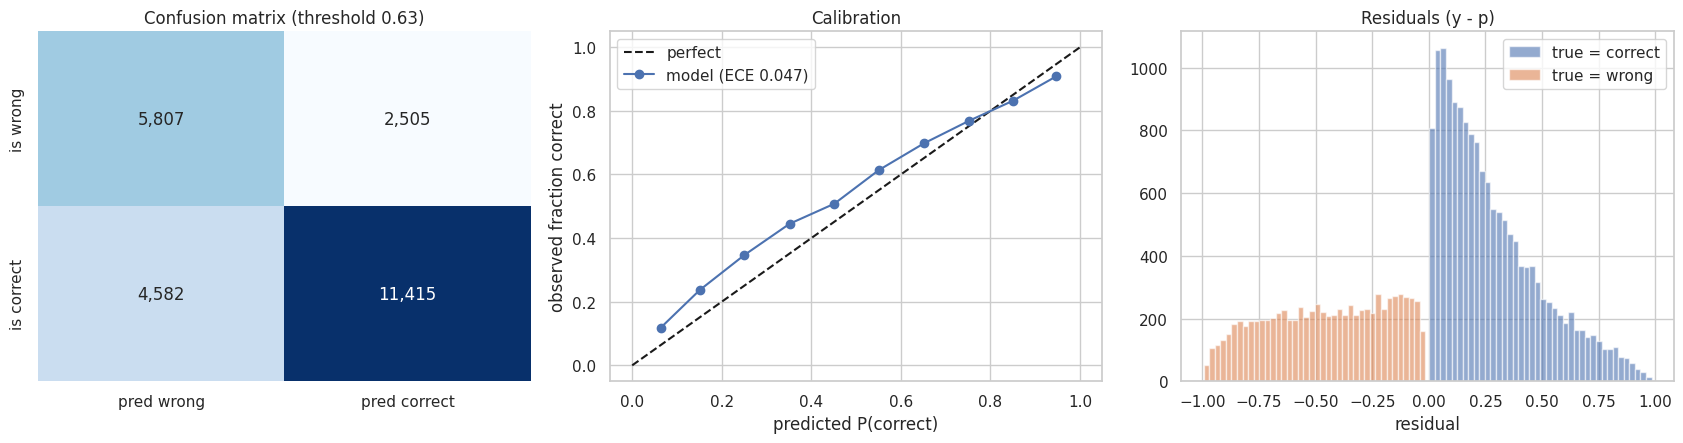

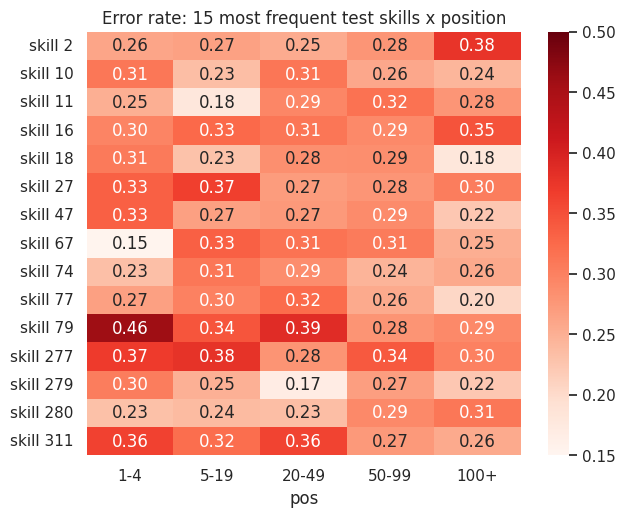

In [21]:
# ---------- 5.1 / 5.2 confusion matrix, calibration, residuals ----------
pred = (pT >= THR).astype(int); cm = confusion_matrix(yi, pred, labels=[0, 1]); tn, fp, fn, tp = cm.ravel()
err = pd.DataFrame({"error type": ["False positive (said correct, was wrong)", "False negative (said wrong, was correct)", "Total errors"],
                    "count": [fp, fn, fp + fn], "share of all predictions": [fp / len(yi), fn / len(yi), (fp + fn) / len(yi)],
                    "share of errors": [fp / (fp + fn), fn / (fp + fn), 1.0]})
display(save_table(err.round(4), "5_1_error_types").style.format({"count": "{:,}"}).hide(axis="index"))
print(f"Over-/under-prediction: mean predicted P(correct) {pT.mean():.3f} vs observed {yi.mean():.3f} -> {'over' if pT.mean() > yi.mean() else 'under'}-prediction by {abs(pT.mean() - yi.mean()):.3f}")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax[0], xticklabels=["pred wrong", "pred correct"], yticklabels=["is wrong", "is correct"])
ax[0].set_title(f"Confusion matrix (threshold {THR:.2f})")
bins = np.minimum((pT * 10).astype(int), 9); cx = [pT[bins == k].mean() for k in range(10) if (bins == k).any()]; cy = [yi[bins == k].mean() for k in range(10) if (bins == k).any()]
ax[1].plot([0, 1], [0, 1], "k--", label="perfect"); ax[1].plot(cx, cy, "o-", label=f"model (ECE {ece(yi, pT):.3f})"); ax[1].set(title="Calibration", xlabel="predicted P(correct)", ylabel="observed fraction correct"); ax[1].legend()
resid = yi - pT; ax[2].hist(resid[yi == 1], bins=40, alpha=.6, label="true = correct"); ax[2].hist(resid[yi == 0], bins=40, alpha=.6, label="true = wrong")
ax[2].set(title="Residuals (y - p)", xlabel="residual"); ax[2].legend(); plt.tight_layout(); save_fig("5_confusion_calibration_residuals"); plt.show()

# error heatmap: error rate by skill x position bucket (top skills)
top = T.skill.value_counts().index[:15]; pb = pd.cut(T.pos, [0, 5, 20, 50, 100, 10**9], right=False, labels=["1-4", "5-19", "20-49", "50-99", "100+"])
H = pd.DataFrame({"skill": T.skill.values, "pos": pb, "err": (pred != yi).astype(int)}); H = H[H.skill.isin(top)]
inv_skill = {v: k for k, v in skill_to_idx.items()}
piv = H.pivot_table(index="skill", columns="pos", values="err", aggfunc="mean", observed=False); piv.index = [f"skill {inv_skill.get(i, i)}" for i in piv.index]
plt.figure(figsize=(7, 5.5)); sns.heatmap(piv, annot=True, fmt=".2f", cmap="Reds", vmin=0.15, vmax=0.5); plt.title("Error rate: 15 most frequent test skills x position"); save_fig("5_error_heatmap"); plt.show()

In [22]:
# ---------- 5.3 qualitative: most confident mistakes ----------
inv_q = {v: k for k, v in question_to_idx.items()}
def show_cases(mask, title, n=5):
    d = T[mask].assign(p=pT[mask]); d = d.assign(conf=np.abs(d.p - d.y)).sort_values("conf", ascending=False).head(n)
    rows = []
    for ix, r in d.iterrows():
        h = test_chunks[int(r.win)][1][max(0, int(r.pos) - 6):int(r.pos)]
        rows.append({"student": T.uid.loc[ix], "step": int(r.pos), "skill": inv_skill.get(int(r.skill)), "question": inv_q.get(int(r.q)), "last answers (1=right)": " ".join(map(str, h)),
                     "true": int(r.y), "P(correct)": round(float(r.p), 3), "question seen in train": int(tr_q_n[int(r.q)])})
    print(title); display(pd.DataFrame(rows).style.hide(axis="index"))
show_cases((pred == 1) & (yi == 0), "Most confident FALSE POSITIVES (predicted correct, was wrong):")
show_cases((pred == 0) & (yi == 1), "Most confident FALSE NEGATIVES (predicted wrong, was correct):")

# ---------- 5.4 root-cause table and question-level suspect-label export ----------
E = (pred != yi)
seen = tr_q_n[T.q.values]
conf = np.abs(pT - yi)

# Define high-mastery students from TRAIN data only: >=20 training attempts and
# >=80% accuracy. A question is a suspect-label candidate only when at least
# five high-mastery training students attempted it and their pooled accuracy
# is >=80%, while the current model makes a confident test error on it.
train_student_stats = data[data.user_id.isin(set(train_ids))].groupby("user_id").correct.agg(["count", "mean"])
high_mastery_ids = set(train_student_stats.index[(train_student_stats["count"] >= 20) & (train_student_stats["mean"] >= 0.80)])
hm_data = data[data.user_id.isin(high_mastery_ids)].copy()
hm_q = hm_data.groupby("question_idx").correct.agg(hm_attempts="count", hm_correct="sum")
hm_q["hm_accuracy"] = hm_q.hm_correct / hm_q.hm_attempts.clip(lower=1)
hm_attempts = hm_q.hm_attempts.reindex(T.q.values).fillna(0).to_numpy()
hm_accuracy = hm_q.hm_accuracy.reindex(T.q.values).fillna(np.nan).to_numpy()

suspect_mask = E & (conf >= 0.80) & (hm_attempts >= 5) & (hm_accuracy >= 0.80)
sparse_mask = E & (seen < 5)
short_history_mask = E & (T.pos.values < 5) & ~sparse_mask
confident_error_mask = E & (seen >= 5) & (seen < 20) & (conf >= 0.80) & ~suspect_mask
capacity_mask = E & (seen >= 20) & ~suspect_mask & (conf >= 0.80)
uncertain_mask = E & (np.abs(pT - 0.5) < 0.10) & ~(sparse_mask | short_history_mask | suspect_mask | confident_error_mask | capacity_mask)
assigned = sparse_mask | short_history_mask | suspect_mask | confident_error_mask | capacity_mask | uncertain_mask
other_mask = E & ~assigned

bucket_masks = [
    ("Sparse question evidence (<5 train attempts)", sparse_mask),
    ("Limited history (<5 prior steps)", short_history_mask),
    ("Suspect label candidate (high-mastery accuracy >=80%)", suspect_mask),
    ("Confident error (question seen 5-19 times)", confident_error_mask),
    ("Capacity-limit candidate (seen >=20; confident error; not suspect-label)", capacity_mask),
    ("Low-confidence / ambiguous prediction", uncertain_mask),
    ("Other", other_mask),
]
rc = pd.DataFrame([{"root-cause bucket": name, "errors": int(mask.sum()), "share of errors": float(mask.sum() / max(E.sum(), 1))} for name, mask in bucket_masks])
display(save_table(rc.round(4), "5_4_root_causes").style.format({"errors": "{:,}"}).hide(axis="index"))
print("Definitions are diagnostic heuristics, not proof of mislabeled data or true cognitive capacity. Buckets are mutually exclusive; Other is the residual category.")
SUMMARY["root_causes"] = dict(zip(rc["root-cause bucket"], rc.errors.astype(int)))

# Export test error rows and aggregated questions for manual review.
sus_rows = T.loc[suspect_mask, ["q", "skill", "pos", "uid", "y"]].copy()
sus_rows["prediction"] = pT[suspect_mask]
sus_rows["confidence_error"] = conf[suspect_mask]
sus_rows["train_question_attempts"] = seen[suspect_mask]
sus_rows["high_mastery_attempts"] = hm_attempts[suspect_mask]
sus_rows["high_mastery_accuracy"] = hm_accuracy[suspect_mask]
sus_rows["question_id"] = sus_rows.q.map(inv_q)
sus_rows["skill_id_first_skill_diagnostic"] = sus_rows.skill.map(inv_skill)
sus_rows["review_reason"] = "Confident test error; question accuracy among high-mastery training students >=80% (n>=5)"
sus_rows.to_csv(os.path.join(M5_OUT, "suspect_label_error_rows.csv"), index=False)
if len(sus_rows):
    suspect_questions = (sus_rows.groupby(["q", "question_id"], dropna=False)
        .agg(suspect_label_errors=("y", "size"), incorrect_responses=("y", lambda x: int((x == 0).sum())),
             correct_responses=("y", lambda x: int((x == 1).sum())), mean_model_probability=("prediction", "mean"),
             mean_abs_error_confidence=("confidence_error", "mean"), train_question_attempts=("train_question_attempts", "first"),
             high_mastery_attempts=("high_mastery_attempts", "first"), high_mastery_accuracy=("high_mastery_accuracy", "first"))
        .reset_index())
    # Include the question's observed training accuracy for context.
    q_train_acc = (tr_q_c / np.maximum(tr_q_n, 1))
    suspect_questions["overall_train_accuracy"] = suspect_questions.q.map(lambda q: float(q_train_acc[int(q)]))
    suspect_questions["review_reason"] = "High-mastery students mostly correct; inspect item wording, key and scoring"
else:
    suspect_questions = pd.DataFrame(columns=["q", "question_id", "suspect_label_errors", "incorrect_responses", "correct_responses", "mean_model_probability", "mean_abs_error_confidence", "train_question_attempts", "high_mastery_attempts", "high_mastery_accuracy", "overall_train_accuracy", "review_reason"])
suspect_questions.to_csv(os.path.join(M5_OUT, "suspect_label_questions.csv"), index=False)
print(f"Suspect-label candidates: {int(suspect_mask.sum()):,} test error rows across {len(suspect_questions):,} questions. Exported suspect_label_questions.csv and suspect_label_error_rows.csv to {M5_OUT}.")
SUMMARY["suspect_label_error_rows"] = int(suspect_mask.sum())
SUMMARY["suspect_label_question_count"] = int(len(suspect_questions))


Most confident FALSE POSITIVES (predicted correct, was wrong):


student,step,skill,question,last answers (1=right),true,P(correct),question seen in train
85201,28,51,53319,1 0 0 1 1 1,0,0.994000,11
78974,13,15,93547,1 0 1 1 0 1,0,0.992000,6
80353,14,15,57917,1 1 0 1 1 1,0,0.992000,13
78710,51,50,97892,1 1 0 1 1 1,0,0.991000,77
79319,125,105,75226,1 1 1 1 1 0,0,0.991000,7


Most confident FALSE NEGATIVES (predicted wrong, was correct):


student,step,skill,question,last answers (1=right),true,P(correct),question seen in train
79460,1,92,90657,0,1,0.016000,3
80234,79,81,61616,0 1 0 0 0 0,1,0.025000,18
81909,35,77,85219,0 0 0 0 0 0,1,0.028000,6
81909,76,77,108945,0 1 1 0 0 0,1,0.028000,89
81909,25,77,85216,0 0 0 0 0 0,1,0.029000,11


root-cause bucket,errors,share of errors
Sparse question evidence (<5 train attempts),533,0.075200
Limited history (<5 prior steps),502,0.070800
Suspect label candidate (high-mastery accuracy >=80%),466,0.065800
Confident error (question seen 5-19 times),547,0.077200
Capacity-limit candidate (seen >=20; confident error; not suspect-label),392,0.055300
Low-confidence / ambiguous prediction,"2,046",0.288700
Other,"2,754",0.388600


Definitions are diagnostic heuristics, not proof of mislabeled data or true cognitive capacity. Buckets are mutually exclusive; Other is the residual category.
Suspect-label candidates: 466 test error rows across 406 questions. Exported suspect_label_questions.csv and suspect_label_error_rows.csv to exports/eval_outputs.


## M5-6. Robustness and interpretability

The inputs are discrete (skill ids, question ids, right/wrong), so classic pixel/text noise does not apply. The stress tests are the discrete analogues: **flipped answers** (noisy logging), **missing skill tags** and **missing question ids** (missing fields), and **meaning-based attacks** (inverting the whole history, shuffling the order). In every test the *true labels stay fixed* and only the model's inputs are corrupted.

**Interpretability caveat.** Attention maps (when the selected model has attention) show where the architecture allocates attention; they are not causal explanations. Leave-one-out answer flips are sensitivity tests, not proof that a feature caused a prediction. The shortcut checks provide complementary evidence about reliance on answer history, skill IDs and question IDs.

**OOD boundary.** The OOD analysis below is *within-dataset slice testing* (rare/unseen questions, rare skills, long histories and later-starting students). It is not an external-domain test. No claim of generalisation to another ASSISTments year, school system or platform is made because no external dataset is supplied and the learned ID embeddings are dataset-specific.

stress,rate,AUC,drop
flipped history answers,0.050000,0.770200,0.007100
flipped history answers,0.100000,0.761500,0.015900
flipped history answers,0.200000,0.741900,0.035500
flipped history answers,0.500000,0.647600,0.129800
flipped history answers,1.000000,0.460200,0.317200
missing skill tags,0.050000,0.768700,0.008700
missing skill tags,0.100000,0.759600,0.017700
missing skill tags,0.200000,0.742800,0.034600
missing skill tags,0.500000,0.689100,0.088300
missing skill tags,1.000000,0.503000,0.274400


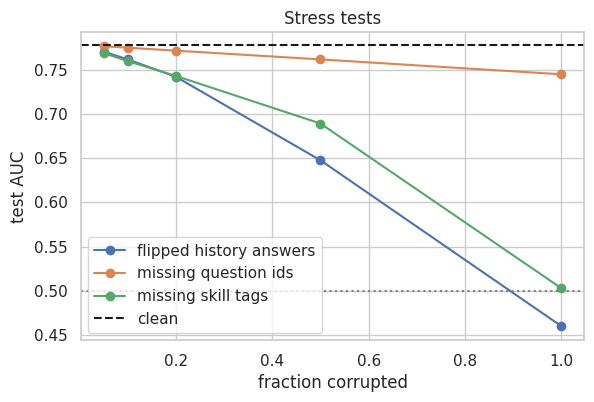

flipped past answers (k),AUC,AUC drop,relative AUC drop (%)
1,0.765600,0.011800,1.518000
3,0.747600,0.029700,3.826100
5,0.734800,0.042600,5.475400


Greedy attack changes only historical input answers; target labels are unchanged. Runtime can be substantial because each candidate flip is evaluated.
Order shuffle: AUC 0.7774 -> 0.7422 (drop +0.0352); all history inverted: AUC 0.4602


history,mean P(correct)
real,0.620900
last 5 forced WRONG,0.403800
last 5 forced RIGHT,0.743400


Directional check: right-streak prediction >= wrong-streak prediction in 99.4% of 311 cases (mean effect +0.340).


slice,n,base rate,AUC,AUC logistic baseline,Accuracy,ECE,mean p - mean y
in-distribution: question seen >= 20 times,13653,0.641500,0.780500,0.753000,0.709800,0.039700,-0.024800
OOD: question never seen in training,109,0.596300,0.737800,0.748600,0.688100,0.174000,-0.023100
OOD: rare skill (bottom third),8473,0.653100,0.770900,0.750800,0.688900,0.060800,-0.041300
OOD: long history (position >= 150),2926,0.688000,0.779000,0.766300,0.708100,0.049500,-0.039100
OOD: students who started latest (top quartile of start time),4337,0.713600,0.751600,0.742900,0.712700,0.051700,-0.027700
reference: students who started earlier,19972,0.646000,0.780900,0.755500,0.707500,0.046300,-0.027300


OOD scope: these are within-ASSISTments stress slices only. External domain-shift testing (new year, school system or platform) was NOT RUN because no independent external dataset is supplied; dataset-specific skill/question embeddings also prevent direct transfer without adaptation.


In [23]:
# ---------- 6.1 stress tests ----------
REPS = 3; clean = test_auc_now
def flip(ch, r, g):    return [(s, np.where(g.random(len(c)) < r, 1 - c, c), q) for s, c, q in ch]
def mask_sk(ch, r, g): return [(np.where((g.random(len(s)) < r)[:, None], PAD_SKILL, s), c, q) for s, c, q in ch]
def mask_q(ch, r, g):  return [(s, c, np.where(g.random(len(q)) < r, PAD_QUESTION, q)) for s, c, q in ch]
def auc_corrupt(fn, r):
    return float(np.mean([roc_auc_score(*forward_chunks(model, fn(test_chunks, r, np.random.default_rng(SEED + k)), test_chunks)) for k in range(REPS)]))
stress = []
for name, fn in [("flipped history answers", flip), ("missing skill tags", mask_sk), ("missing question ids", mask_q)]:
    for r in [0.05, 0.10, 0.20, 0.50, 1.00]:
        a = auc_corrupt(fn, r); stress.append({"stress": name, "rate": r, "AUC": a, "drop": clean - a})
stress = pd.DataFrame(stress); display(save_table(stress.round(4), "6_1_stress_tests").style.hide(axis="index"))
plt.figure(figsize=(6.5, 4))
for n, g in stress.groupby("stress"): plt.plot(g.rate, g.AUC, "o-", label=n)
plt.axhline(clean, color="k", ls="--", label="clean"); plt.axhline(0.5, color="grey", ls=":"); plt.xlabel("fraction corrupted"); plt.ylabel("test AUC"); plt.legend(); plt.title("Stress tests"); save_fig("6_1_stress"); plt.show()
SUMMARY["auc_drop_10pct_flip"] = float(stress[(stress.stress == "flipped history answers") & (stress.rate == 0.10)]["drop"].iloc[0])

# ---------- 6.1b worst-case greedy historical-answer attack ----------
# For each window, greedily flip the one still-unmodified past answer that
# maximises the total absolute change in that window's prediction vector.
# Ground-truth target labels are held fixed throughout. This is a stress test,
# not a claim that an attacker can necessarily observe model internals.
def greedy_window_attack(chunks, budgets=(1, 3, 5), candidate_batch=128):
    max_k = max(budgets)
    attacked_by_k = {k: [] for k in budgets}
    labels_ref = []
    for wi, (s0, c0, q0) in enumerate(chunks):
        base_y, base_p = forward_chunks(model, [(s0, c0, q0)], [(s0, c0, q0)], bs=1)
        labels_ref.append(base_y)
        current_c = c0.copy()
        current_p = base_p.copy()
        chosen = set()
        n_past = max(0, len(c0) - 1)  # last answer has no subsequent target in this window
        for step in range(1, min(max_k, n_past) + 1):
            cand_positions = [j for j in range(n_past) if j not in chosen]
            if not cand_positions:
                break
            candidate_chunks = []
            for j in cand_positions:
                cc = current_c.copy(); cc[j] = 1 - cc[j]
                candidate_chunks.append((s0, cc, q0))
            _, candidate_probs = forward_chunks(model, candidate_chunks,
                [(s0, c0, q0)] * len(candidate_chunks), bs=candidate_batch)
            # forward_chunks concatenates predictions; each candidate has the same length.
            n_pred = len(current_p)
            candidate_probs = candidate_probs.reshape(len(cand_positions), n_pred)
            impacts = np.abs(candidate_probs - current_p[None, :]).sum(axis=1)
            best_idx = int(np.argmax(impacts)); best_pos = cand_positions[best_idx]
            current_c[best_pos] = 1 - current_c[best_pos]
            current_p = candidate_probs[best_idx].copy(); chosen.add(best_pos)
            if step in budgets:
                attacked_by_k[step].append(current_p.copy())
        # If a window is shorter than a requested budget, retain its strongest
        # available attack so all windows remain represented at each budget.
        for k in budgets:
            if len(attacked_by_k[k]) < wi + 1:
                attacked_by_k[k].append(current_p.copy())
    y_all = np.concatenate(labels_ref)
    rows = []
    for k in budgets:
        p_all = np.concatenate(attacked_by_k[k])
        auc_k = float(roc_auc_score(y_all, p_all))
        rows.append({"flipped past answers (k)": k, "AUC": auc_k, "AUC drop": float(clean - auc_k),
                     "relative AUC drop (%)": float(100 * (clean - auc_k) / clean) if clean else np.nan})
    return pd.DataFrame(rows)

worst_case = greedy_window_attack(test_chunks, budgets=(1, 3, 5))
display(save_table(worst_case.round(4), "6_1b_worst_case_greedy_attack").style.hide(axis="index"))
SUMMARY["worst_case_greedy_attack"] = worst_case.to_dict(orient="records")
print("Greedy attack changes only historical input answers; target labels are unchanged. Runtime can be substantial because each candidate flip is evaluated.")

# adversarial, meaning-based: shuffle each window's order (labels move with the steps)
shuf = [(s[p_], c[p_], q[p_]) for (s, c, q), p_ in ((ch, np.random.default_rng(SEED + i).permutation(len(ch[1]))) for i, ch in enumerate(test_chunks))]
sh_auc = roc_auc_score(*forward_chunks(model, shuf)); print(f"Order shuffle: AUC {clean:.4f} -> {sh_auc:.4f} (drop {clean - sh_auc:+.4f}); all history inverted: AUC {stress[(stress.stress=='flipped history answers') & (stress.rate==1.0)]['AUC'].iloc[0]:.4f}")

# directional (behavioural) test: right-streak must predict >= wrong-streak
def last_probs(chs):
    _, P = forward_chunks(model, chs); return P[np.cumsum([len(c[1]) - 1 for c in chs]) - 1]
dr = np.random.default_rng(SEED); KS = 5; cand = [j for j, ch in enumerate(test_chunks) if len(ch[0]) >= KS + 6]; pick = dr.choice(cand, size=min(600, len(cand)), replace=False)
base_c, wrong_c, right_c = [], [], []
for j in pick:
    s, c, q = test_chunks[j]; t = int(dr.integers(KS + 1, len(c))); s2, q2, c2 = s[:t + 1], q[:t + 1], c[:t + 1].copy(); cw, cr = c2.copy(), c2.copy(); cw[t - KS:t] = 0; cr[t - KS:t] = 1
    base_c.append((s2, c2, q2)); wrong_c.append((s2, cw, q2)); right_c.append((s2, cr, q2))
pb_, pw_, pr_ = last_probs(base_c), last_probs(wrong_c), last_probs(right_c)
display(pd.DataFrame({"history": ["real", f"last {KS} forced WRONG", f"last {KS} forced RIGHT"], "mean P(correct)": [pb_.mean(), pw_.mean(), pr_.mean()]}).round(4).style.hide(axis="index"))
SUMMARY["directional_pass"] = float(np.mean(pr_ >= pw_)); SUMMARY["streak_effect"] = float(pr_.mean() - pw_.mean())
print(f"Directional check: right-streak prediction >= wrong-streak prediction in {SUMMARY['directional_pass']:.1%} of {len(pb_)} cases (mean effect {SUMMARY['streak_effect']:+.3f}).")

# ---------- 6.2 out-of-distribution slices (inside ASSISTments) ----------
first_ord = data.groupby("user_id")["order_id"].min(); late_cut = first_ord.quantile(0.75)
late = T.uid.map(first_ord).values >= late_cut
ood = pd.DataFrame([slice_row("in-distribution: question seen >= 20 times", qn >= 20), slice_row("OOD: question never seen in training", qn == 0), slice_row("OOD: rare skill (bottom third)", freq <= f1_),
                    slice_row("OOD: long history (position >= 150)", T.pos >= 150), slice_row("OOD: students who started latest (top quartile of start time)", late),
                    slice_row("reference: students who started earlier", ~late)])
display(save_table(ood.round(4), "6_2_ood").style.hide(axis="index"))
print("OOD scope: these are within-ASSISTments stress slices only. External domain-shift testing (new year, school system or platform) was NOT RUN because no independent external dataset is supplied; dataset-specific skill/question embeddings also prevent direct transfer without adaptation.")
SUMMARY["external_ood_test"] = "NOT RUN — no independent external dataset supplied"
SUMMARY["internal_ood_slices"] = ["unseen/rare questions", "rare skills", "long histories", "later-starting students"]

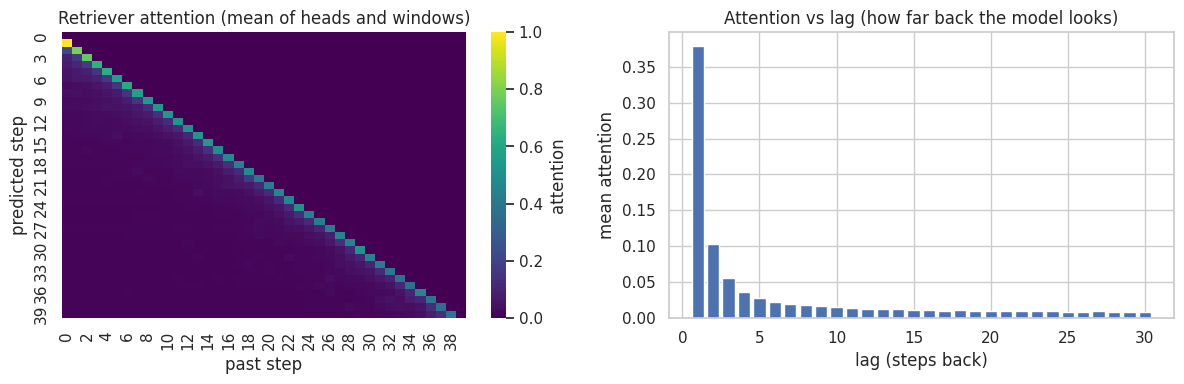

Learned decay theta (mean over heads/layers): 0.701. Attention is concentrated on recent steps: 67% of the weight sits in the last 5 steps.


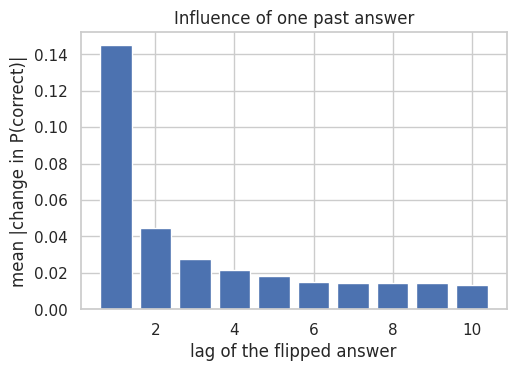

Learned Rasch difficulty vs observed question error rate (questions with >= 20 attempts, n=3325): Spearman rho = +0.084 (positive = harder questions got higher difficulty).


input condition,test AUC,drop vs real
real inputs,0.777400,0.000000
history answers replaced by random answers at the same rate,0.661700,0.115600
"skill ids randomly relabelled (content destroyed, history kept)",0.590500,0.186900
no question ids (all questions treated as unseen),0.744600,0.032700
baseline: student running accuracy only,0.673000,0.104400
baseline: question rate only,0.691800,0.085500


Reading guide: a model that learned real knowledge tracing loses most of its AUC when the answer history is randomised, and stays above the student-accuracy baseline because it also uses skill/question content. If relabelled skills barely hurt, the model is mostly using the student's overall ability, not skill content.


In [24]:
# ---------- 6.3 interpretability ----------
# (a) AKT attention maps (the model's own "feature importance" over past steps)
def attn_weights(a, q, k, v, allow_diagonal, zero_pad):
    B, L, _ = q.shape; sp = lambda x: x.view(B, L, a.h, a.dk).transpose(1, 2)
    q_, k_ = sp(a.q_lin(q)), sp(a.k_lin(k)); sc = torch.matmul(q_, k_.transpose(-1, -2)) / math.sqrt(a.dk)
    i, j = torch.arange(L, device=q.device).unsqueeze(1), torch.arange(L, device=q.device).unsqueeze(0); al = (j <= i) if allow_diagonal else (j < i)
    s = torch.softmax(sc.masked_fill(~al, -1e32), -1) * al; rem = s.sum(-1, keepdim=True) - s.cumsum(-1); dist = (rem * (i - j).abs().float()).clamp(min=0).sqrt()
    w = torch.softmax((sc * torch.exp(-F.softplus(a.gammas) * dist).clamp(1e-5, 1e5)).masked_fill(~al, -1e32), -1)
    if zero_pad: w = torch.cat([torch.zeros_like(w[:, :, :1]), w[:, :, 1:]], 2)
    return w
if isinstance(model, AKT):
    att = model.retriever[0].attn; store = []; orig = att.forward
    def patched(q, k, v, allow_diagonal, zero_pad=False):
        store.append(attn_weights(att, q, k, v, allow_diagonal, zero_pad).detach().cpu()); return orig(q, k, v, allow_diagonal, zero_pad)
    att.forward = patched
    try:
        long_w = [c for c in test_chunks if len(c[0]) >= 60][:40]; forward_chunks(model, long_w, bs=8)
    finally:
        del att.forward
    W = torch.cat([w[:, :, :60, :60].
                   mean(1) for w in store if w.shape[-1] >= 60]).mean(0).numpy()          # mean over heads and windows
    lag = [np.mean([W[t, t - l] for t in range(30, 60)]) for l in range(1, 31)]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4)); sns.heatmap(W[:40, :40], cmap="viridis", ax=ax[0], cbar_kws={"label": "attention"}); ax[0].set(title="Retriever attention (mean of heads and windows)", xlabel="past step", ylabel="predicted step")
    ax[1].bar(range(1, 31), lag); ax[1].set(title="Attention vs lag (how far back the model looks)", xlabel="lag (steps back)", ylabel="mean attention"); plt.tight_layout(); save_fig("6_3_attention"); plt.show()
    print(f"Learned decay theta (mean over heads/layers): {model.decay.mean().item():.3f}. Attention is concentrated on recent steps: {sum(lag[:5]) / sum(lag):.0%} of the weight sits in the last 5 steps.")
else:
    print(f"{M5_NAME} has no attention weights: skipping the attention map (the influence test below applies to every model).")

# (b) leave-one-out influence: flip ONE past answer, measure |change in the next prediction|
ir = np.random.default_rng(SEED); cand = [c for c in test_chunks if len(c[0]) >= 25][:400]; infl = {l: [] for l in range(1, 11)}
base_t, cuts = [], []
for s, c, q in cand:
    t = int(ir.integers(15, len(c))); cuts.append((s[:t + 1], c[:t + 1], q[:t + 1]))
p0 = last_probs(cuts)
for l in infl:
    mod = []
    for s, c, q in cuts:
        c2 = c.copy(); c2[len(c) - 1 - l] = 1 - c2[len(c) - 1 - l]; mod.append((s, c2, q))
    infl[l] = np.abs(last_probs(mod) - p0).mean()
plt.figure(figsize=(5.5, 3.6)); plt.bar(list(infl), list(infl.values())); plt.xlabel("lag of the flipped answer"); plt.ylabel("mean |change in P(correct)|"); plt.title("Influence of one past answer"); save_fig("6_3_influence"); plt.show()
SUMMARY["influence_lag1"], SUMMARY["influence_lag10"] = float(infl[1]), float(infl[10])

# (c) Rasch difficulty vs real question difficulty (question-aware AKT only)
if hasattr(model, "difficulty") and getattr(model, "use_rasch", False):
    ok = tr_q_n[:Q] >= 20; mu = model.difficulty.weight.detach().cpu().numpy()[:Q, 0]; hard = 1 - tr_q_c[:Q] / np.maximum(tr_q_n[:Q], 1)
    rho = spearmanr(mu[ok], hard[ok]).correlation; print(f"Learned Rasch difficulty vs observed question error rate (questions with >= 20 attempts, n={ok.sum()}): Spearman rho = {rho:+.3f} (positive = harder questions got higher difficulty).")
    SUMMARY["rasch_rho"] = float(rho)

# (d) shortcut checks: what does the AUC depend on?
g2 = np.random.default_rng(SEED); allc = np.concatenate([c for _, c, _ in test_chunks]); rate = allc.mean()
rand_hist = [(s, (g2.random(len(c)) < rate).astype(c.dtype), q) for s, c, q in test_chunks]
perm_sk = g2.permutation(N); perm_map = np.append(perm_sk, PAD_SKILL); skill_perm = [(perm_map[s], c, q) for s, c, q in test_chunks]
sc_rows = [("real inputs", clean), ("history answers replaced by random answers at the same rate", roc_auc_score(*forward_chunks(model, rand_hist, test_chunks))),
           ("skill ids randomly relabelled (content destroyed, history kept)", roc_auc_score(*forward_chunks(model, skill_perm, test_chunks))),
           ("no question ids (all questions treated as unseen)", roc_auc_score(*forward_chunks(model, mask_q(test_chunks, 1.0, g2), test_chunks))),
           ("baseline: student running accuracy only", roc_auc_score(yT, BT["Student running accuracy"])), ("baseline: question rate only", roc_auc_score(yT, BT["Question rate"]))]
sc = pd.DataFrame(sc_rows, columns=["input condition", "test AUC"]); sc["drop vs real"] = clean - sc["test AUC"]
display(save_table(sc.round(4), "6_3_shortcut_checks").style.hide(axis="index"))
print("Reading guide: a model that learned real knowledge tracing loses most of its AUC when the answer history is randomised, and stays above the student-accuracy baseline "
      "because it also uses skill/question content. If relabelled skills barely hurt, the model is mostly using the student's overall ability, not skill content.")

## M5-7. Limitations and operational constraints

**Documented boundaries of this model** (confirmed by the tests above, summarised again in M5-10)
- **Vocabulary:** only the skill ids and question ids seen in the data are known. Unknown questions must be sent as the padding id (the "missing question ids" stress test shows the cost); unknown skills cannot be handled without retraining.
- **Window:** trained on windows of at most `MAX_LEN` steps; longer histories are cut into windows and the model forgets everything before the current window.
- **Cold start:** the first steps of a student and questions never seen in training are the weakest slices (M5-4.3).
- **Data quality:** wrong or missing answer logs degrade predictions gradually (M5-6.1); a fully inverted history makes the model confidently wrong.
- **Domain:** valid for ASSISTments-style maths practice. Other platforms need retraining or fine-tuning (embeddings are dataset-specific).

**Bias and ethics.** ASSISTments 2009-10 contains **no demographic fields**, so demographic fairness cannot be measured. The notebook uses *proxies*: student ability bands and history length. Remaining risks: the model learns from past performance, so it can **lock in low expectations** for strugglers if used to gate content; predictions are probabilities, not diagnoses; and the data come from specific US schools, so results may not transfer to other populations. Recommended use: *decision support* for a teacher or an adaptive tutor with a human override, never an automatic high-stakes decision (grades, placement).

In [25]:
# ---------- 7.1 computational efficiency ----------
def sync(): 
    if torch.cuda.is_available(): torch.cuda.synchronize()
def time_window(m, L, reps=100):
    ch = next(c for c in test_chunks if len(c[0]) >= L); b = [t.to(next(m.parameters()).device) for t in collate([tuple(x[:L] for x in ch)])]
    with torch.no_grad():
        for _ in range(10): m(b[0], b[1], b[2], b[4], b[5], b[6])
        ts = []
        for _ in range(reps): sync(); t0 = time.perf_counter(); m(b[0], b[1], b[2], b[4], b[5], b[6]); sync(); ts.append((time.perf_counter() - t0) * 1000)
    return float(np.median(ts)), float(np.percentile(ts, 95))
Lmax = min(200, max(len(c[0]) for c in test_chunks)); L50 = min(50, Lmax)
lat50, lat200 = time_window(model, L50), time_window(model, Lmax)
if torch.cuda.is_available(): torch.cuda.reset_peak_memory_stats()
t0 = time.perf_counter(); forward_chunks(model, test_chunks); sync(); dt = time.perf_counter() - t0
size_mb = sum(p.numel() * p.element_size() for p in model.parameters()) / 1e6
eff = pd.DataFrame({"measure": [f"latency, one student window of {L50} steps (ms, median / p95)", f"latency, one student window of {Lmax} steps (ms, median / p95)", "throughput, batch inference (predictions/s)",
                                "throughput, batch inference (student-windows/s)", "parameters", "weights size (MB, fp32)", "process RAM (MB)", "GPU peak memory (MB)"],
                    "value": [f"{lat50[0]:.1f} / {lat50[1]:.1f}", f"{lat200[0]:.1f} / {lat200[1]:.1f}", f"{len(T) / dt:,.0f}", f"{len(test_chunks) / dt:,.0f}", f"{count_params(model):,}", f"{size_mb:.2f}",
                              f"{psutil.Process().memory_info().rss / 1e6:,.0f}" if psutil else "psutil not installed", f"{torch.cuda.max_memory_allocated() / 1e6:.0f}" if torch.cuda.is_available() else "no GPU"]})
display(save_table(eff, "7_1_efficiency").style.hide(axis="index"))
SUMMARY.update({"latency_ms_window200": lat200[0], "throughput_pred_per_s": len(T) / dt, "size_mb": size_mb})
print(f"Device: {device}. One request = re-reading the student's window, so per-prediction cost ~ window latency; a service can cache the encoded history if needed.")

# ---------- 7.1b fresh-process inference memory (model-only load) ----------
# Trace the selected model once, then launch a separate Python process which
# loads ONLY the TorchScript model and synthetic inference tensors. The child
# reports its own process peak RSS and CUDA peak allocated/reserved memory.
import subprocess, sys, tempfile
memory_report = {"status": "not measured", "reason": None}
try:
    sample = collate([test_chunks[0]])
    trace_inputs = tuple(t for j, t in enumerate(sample) if j != 3)  # omit labels; keep ex, ans, target, mask, ex_q, tgt_q
    trace_model = copy.deepcopy(model).cpu().eval()
    traced_path = os.path.join(M5_OUT, "inference_model_trace.pt")
    traced = torch.jit.trace(trace_model, trace_inputs, strict=False)
    traced.save(traced_path)
    seq_len = int(trace_inputs[0].shape[1]); skill_slots = int(trace_inputs[0].shape[2])
    child_code = r"""import sys, json, time, torch
try:
    import psutil
except Exception:
    psutil = None
path, seq_len, slots, device = sys.argv[1], int(sys.argv[2]), int(sys.argv[3]), sys.argv[4]
dev = torch.device(device if device == "cpu" or torch.cuda.is_available() else "cpu")
proc = psutil.Process() if psutil else None
rss_start = proc.memory_info().rss / 1e6 if proc else None
m = torch.jit.load(path, map_location=dev).eval()
L, K = seq_len, slots
ex = torch.zeros((1,L,K), dtype=torch.long, device=dev); ans = torch.zeros_like(ex); tgt = torch.zeros_like(ex)
mask = torch.ones((1,L), dtype=torch.bool, device=dev); exq = torch.zeros((1,L), dtype=torch.long, device=dev); tgq = torch.zeros_like(exq)
if dev.type == "cuda": torch.cuda.reset_peak_memory_stats(dev)
with torch.inference_mode():
    for _ in range(10): m(ex, ans, tgt, mask, exq, tgq)
    if dev.type == "cuda": torch.cuda.synchronize(dev); torch.cuda.reset_peak_memory_stats(dev)
    peak_rss = rss_start or 0
    for _ in range(50):
        m(ex, ans, tgt, mask, exq, tgq)
        if proc: peak_rss = max(peak_rss, proc.memory_info().rss / 1e6)
    if dev.type == "cuda": torch.cuda.synchronize(dev)
out = {"device": str(dev), "batch_size": 1, "sequence_length": L,
       "cpu_rss_start_mb": rss_start, "cpu_peak_rss_mb": peak_rss if proc else None,
       "gpu_peak_allocated_mb": torch.cuda.max_memory_allocated(dev)/1e6 if dev.type == "cuda" else None,
       "gpu_peak_reserved_mb": torch.cuda.max_memory_reserved(dev)/1e6 if dev.type == "cuda" else None,
       "model_parameters": sum(p.numel() for p in m.parameters()) if hasattr(m, "parameters") else None}
print(json.dumps(out))"""
    child_device = "cuda" if torch.cuda.is_available() else "cpu"
    run = subprocess.run([sys.executable, "-c", child_code, traced_path, str(seq_len), str(skill_slots), child_device],
                         capture_output=True, text=True, check=True)
    memory_report = json.loads(run.stdout.strip().splitlines()[-1]); memory_report["status"] = "measured in fresh subprocess"
except Exception as exc:
    memory_report = {"status": "not measured", "reason": repr(exc)}
mem_table = pd.DataFrame([{"measure": k, "value": v} for k, v in memory_report.items()])
display(save_table(mem_table, "7_1b_fresh_process_memory" ).style.hide(axis="index"))
SUMMARY["fresh_process_memory"] = memory_report

# ---------- 7.2 failure modes (worst slices) ----------
fm = slices[(slices.n >= 500) & ~slices["slice"].str.contains("ability")].sort_values("AUC").head(6)[["slice", "n", "AUC", "mean p - mean y"]]
display(save_table(fm.round(4), "7_2_worst_slices").style.format({"n": "{:,}"}).hide(axis="index"))

# ---------- 7.3 fairness proxies ----------
len_band = pd.cut(T.groupby("uid").pos.transform("max"), [0, 20, 50, 100, 10**9], labels=["<=20 steps", "21-50", "51-100", ">100"])
fr = []
for nm, grp in [("student ability*", pd.cut(st_acc, [-.01, a1, a2, 1.01], labels=["low", "middle", "high"])), ("history length in window", len_band)]:
    for lv in grp.dropna().unique():
        m = np.asarray(grp == lv); mm = metrics(yi[m], pT[m], THR)
        fr.append({"group": nm, "level": lv, "n": int(m.sum()), "AUC": mm["AUC"], "FP rate": mm["FP rate"], "FN rate": mm["FN rate"], "mean p - mean y": pT[m].mean() - yi[m].mean()})
fr = pd.DataFrame(fr).sort_values(["group", "level"]); display(save_table(fr.round(4), "7_3_fairness_proxies").style.format({"n": "{:,}"}).hide(axis="index"))
print("* depends on test accuracy, diagnostic only. Low-ability students: high FP rate = the model over-trusts them (missed interventions); gaps in AUC/FP/FN across groups are the fairness signal.")

measure,value
"latency, one student window of 50 steps (ms, median / p95)",4.2 / 4.5
"latency, one student window of 200 steps (ms, median / p95)",4.5 / 4.9
"throughput, batch inference (predictions/s)","48,647"
"throughput, batch inference (student-windows/s)",897
parameters,"491,468"
"weights size (MB, fp32)",1.97
process RAM (MB),"2,358"
GPU peak memory (MB),1416


Device: cuda. One request = re-reading the student's window, so per-prediction cost ~ window latency; a service can cache the encoded history if needed.


measure,value
status,not measured
reason,"CalledProcessError(1, ['/usr/bin/python3', '-c', 'import sys, json, time, torch\ntry:\n import psutil\nexcept Exception:\n psutil = None\npath, seq_len, slots, device = sys.argv[1], int(sys.argv[2]), int(sys.argv[3]), sys.argv[4]\ndev = torch.device(device if device == ""cpu"" or torch.cuda.is_available() else ""cpu"")\nproc = psutil.Process() if psutil else None\nrss_start = proc.memory_info().rss / 1e6 if proc else None\nm = torch.jit.load(path, map_location=dev).eval()\nL, K = seq_len, slots\nex = torch.zeros((1,L,K), dtype=torch.long, device=dev); ans = torch.zeros_like(ex); tgt = torch.zeros_like(ex)\nmask = torch.ones((1,L), dtype=torch.bool, device=dev); exq = torch.zeros((1,L), dtype=torch.long, device=dev); tgq = torch.zeros_like(exq)\nif dev.type == ""cuda"": torch.cuda.reset_peak_memory_stats(dev)\nwith torch.inference_mode():\n for _ in range(10): m(ex, ans, tgt, mask, exq, tgq)\n if dev.type == ""cuda"": torch.cuda.synchronize(dev); torch.cuda.reset_peak_memory_stats(dev)\n peak_rss = rss_start or 0\n for _ in range(50):\n m(ex, ans, tgt, mask, exq, tgq)\n if proc: peak_rss = max(peak_rss, proc.memory_info().rss / 1e6)\n if dev.type == ""cuda"": torch.cuda.synchronize(dev)\nout = {""device"": str(dev), ""batch_size"": 1, ""sequence_length"": L,\n ""cpu_rss_start_mb"": rss_start, ""cpu_peak_rss_mb"": peak_rss if proc else None,\n ""gpu_peak_allocated_mb"": torch.cuda.max_memory_allocated(dev)/1e6 if dev.type == ""cuda"" else None,\n ""gpu_peak_reserved_mb"": torch.cuda.max_memory_reserved(dev)/1e6 if dev.type == ""cuda"" else None,\n ""model_parameters"": sum(p.numel() for p in m.parameters()) if hasattr(m, ""parameters"") else None}\nprint(json.dumps(out))', 'exports/eval_outputs/inference_model_trace.pt', '30', '4', 'cuda'])"


slice,n,AUC,mean p - mean y
previous answer right,"15,979",0.733400,-0.015500
history accuracy > 0.7 (pos>=5),"11,769",0.735800,-0.025200
position in window 1-4,"1,685",0.736100,-0.027900
history accuracy 0.4-0.7 (pos>=5),"9,079",0.748400,-0.030000
previous answer wrong,"8,330",0.761300,-0.050100
position in window 5-19,"4,521",0.765300,-0.031200


group,level,n,AUC,FP rate,FN rate,mean p - mean y
history length in window,21-50,"2,943",0.761900,0.275700,0.340400,-0.019800
history length in window,51-100,"2,990",0.782300,0.251900,0.325800,-0.028700
history length in window,<=20 steps,"1,846",0.775100,0.296800,0.264100,-0.025200
history length in window,>100,"16,530",0.777500,0.318300,0.273800,-0.028700
student ability*,high,"7,917",0.741700,0.523500,0.164100,-0.055100
student ability*,low,"8,113",0.762600,0.161400,0.494800,0.002200
student ability*,middle,"8,279",0.706600,0.418900,0.288700,-0.029700


* depends on test accuracy, diagnostic only. Low-ability students: high FP rate = the model over-trusts them (missed interventions); gaps in AUC/FP/FN across groups are the fairness signal.


## M5-8. Actionable insights and potential improvements

**Short term (no retraining)**
- *Decision threshold:* use the cost-optimal threshold from M5-3 instead of 0.5. The table below shows its effect on test.
- *Post-processing:* recalibrate probabilities with isotonic regression fitted on validation students, and shrink predictions toward the skill rate when the question is new. Both are measured below.
- *Rule-based filters:* do not show "mastered" until at least 5 answers exist; flag predictions on never-seen questions as low-confidence.

**Data cleaning and re-labelling.** Start with the exported `eval_outputs/suspect_label_questions.csv` and its row-level companion `suspect_label_error_rows.csv`. These contain the question IDs, evidence counts and the high-mastery accuracy rule used to flag candidates. Treat them as a manual-review queue, not proof of incorrect labels: inspect the original item, answer key, skill tags and attempt records before changing labels. Review `Confident error (question seen 5-19 times)` separately; these items need more evidence before relabelling.

**Long term**
- Larger or deeper backbone (more AKT blocks, `d_model`), or pre-training on more years of ASSISTments and fine-tuning.
- Multi-task learning (AT-DKT style auxiliary losses, predict next skill and student accuracy).
- Add features the logs contain but this pipeline drops: response time, hints, attempt counts, first-response correctness.
- Explicit cold-start handling: question-text or skill-name embeddings so unseen questions get a sensible prior.

**Data collection and augmentation.** Collect more attempts for rare skills and new questions (the weakest slices); synthesise training sequences by simulating students with a simple mastery model for rare skills; augment by light answer-noise injection and window cropping, which the stress tests suggest is a safe direction (check that AUC on clean data does not fall).

In [26]:
# ---------- 8.1 threshold tuning ----------
thr_tab = pd.DataFrame([{"threshold": t, "val cost/pred": cost_at(yV, pV, t), "test cost/pred": cost_at(yT, pT, t), "test accuracy": ((pT >= t) == yi).mean(),
                         "test FP rate": metrics(yT, pT, t)["FP rate"], "test FN rate": metrics(yT, pT, t)["FN rate"]} for t in [0.3, 0.4, 0.5, 0.6, 0.7, THR]]).drop_duplicates("threshold").sort_values("threshold")
display(save_table(thr_tab.round(4), "8_1_threshold_tuning").style.hide(axis="index"))

# ---------- 8.2 recalibration and cold-start shrinkage (fitted on validation, applied to test) ----------
iso = IsotonicRegression(out_of_bounds="clip", y_min=0.001, y_max=0.999).fit(pV, yV); pT_iso = iso.predict(pT)
sk_T = base_feats(T)[0]; cold = tr_q_n[T.q.values] < 5; pT_shr = np.where(cold, 0.5 * pT + 0.5 * sk_T, pT)
post = pd.DataFrame([{"variant": nm, **{k: metrics(yT, p, THR)[k] for k in ["AUC", "Brier", "LogLoss", "ECE", "Accuracy"]}} for nm, p in
                     [("raw model", pT), ("isotonic recalibration", pT_iso), ("cold-start shrinkage toward skill rate", pT_shr), ("both", np.where(cold, 0.5 * pT_iso + 0.5 * sk_T, pT_iso))]])
display(save_table(post.round(4), "8_2_post_processing").style.hide(axis="index"))

threshold,val cost/pred,test cost/pred,test accuracy,test FP rate,test FN rate
0.300000,0.517500,0.487300,0.736500,0.654500,0.060300
0.400000,0.465400,0.442900,0.743800,0.546200,0.105500
0.500000,0.421500,0.406700,0.742600,0.436600,0.164300
0.600000,0.401300,0.391600,0.721000,0.329300,0.252900
0.630000,0.401100,0.394600,0.708500,0.301400,0.286400
0.700000,0.408900,0.402500,0.674900,0.226500,0.376300


variant,AUC,Brier,LogLoss,ECE,Accuracy
raw model,0.777400,0.177100,0.534100,0.047200,0.708500
isotonic recalibration,0.777100,0.174400,0.525900,0.010000,0.722200
cold-start shrinkage toward skill rate,0.775700,0.177100,0.534000,0.044000,0.709100
both,0.775600,0.174800,0.527100,0.011300,0.723100


## M5-9. Deployment readiness

The cell below compares the FP32 checkpoint with compressed variants on identical student windows. Compression is measured on **CPU copies**; the original checkpoint is not modified. Validation AUC is used to choose a candidate compression variant; test AUC is reported as a final descriptive result and is **not** used to select the variant. The default validation AUC-loss tolerance is 0.01 and should be changed only if the project owner approves a different tolerance.

| Technique | What is done | Important qualification |
|---|---|---|
| Post-training dynamic quantisation | Attempts dynamic INT8 quantisation of supported `Linear` layers | This implementation does not guarantee that every recurrent/attention operation is quantised; inspect the measured result and supported modules. |
| Pruning | Global magnitude pruning of `Linear` weights (30% / 50%) | Unstructured sparsity does not necessarily reduce dense inference latency. The notebook measures file size and latency rather than assuming a speed-up. |
| Knowledge distillation | A small DKT student learns from the selected model's soft predictions plus labels, with a labels-only control | Student training uses training data; epoch selection uses validation AUC. The test set is report-only. |

**Deployment decision rule:** among variants whose validation AUC is no more than `COMPRESSION_AUC_TOL` below the FP32 validation AUC, recommend the smallest model; use latency as a tie-breaker. This is a screening recommendation, not production approval. Hardware-specific load testing is still required.

In [27]:
import torch.nn.utils.prune as prune
cpu_model = copy.deepcopy(model).cpu().eval()
def state_mb(m):
    b = io.BytesIO(); torch.save(m.state_dict(), b); return b.tell() / 1e6
def cpu_lat(m, L=Lmax): return time_window(m, L, reps=60)[0]
rows = [{"variant": "fp32 (this model, CPU)", "params": count_params(cpu_model), "size MB": state_mb(cpu_model),
         "validation AUC": roc_auc_score(*forward_chunks(cpu_model, val_chunks)), "test AUC": roc_auc_score(*forward_chunks(cpu_model, test_chunks)),
         "latency ms (window)": cpu_lat(cpu_model)}]
try:                                                       # int8 dynamic quantisation
    q8 = torch.ao.quantization.quantize_dynamic(copy.deepcopy(cpu_model), {nn.Linear}, dtype=torch.qint8)
    rows.append({"variant": "int8 dynamic quantisation", "params": rows[0]["params"], "size MB": state_mb(q8),
                 "validation AUC": roc_auc_score(*forward_chunks(q8, val_chunks)), "test AUC": roc_auc_score(*forward_chunks(q8, test_chunks)),
                 "latency ms (window)": cpu_lat(q8)})
except Exception as e:
    print("int8 quantisation not available for this model/torch build:", repr(e)[:150])
for amt in [0.3, 0.5]:                                     # global magnitude pruning
    pm = copy.deepcopy(cpu_model); pars = [(mod, "weight") for mod in pm.modules() if isinstance(mod, nn.Linear)]
    prune.global_unstructured(pars, pruning_method=prune.L1Unstructured, amount=amt)
    for mod, nme in pars: prune.remove(mod, nme)
    tot = sum(mod.weight.numel() for mod, _ in pars); z = sum(int((mod.weight == 0).sum()) for mod, _ in pars)
    rows.append({"variant": f"pruned {int(amt * 100)}% of Linear weights ({z / tot:.0%} zeros)", "params": rows[0]["params"], "size MB": state_mb(pm),
                     "validation AUC": roc_auc_score(*forward_chunks(pm, val_chunks)), "test AUC": roc_auc_score(*forward_chunks(pm, test_chunks)),
                     "latency ms (window)": cpu_lat(pm)})

if RUN_DISTILLATION:
    def train_student(alpha, epochs=DISTILL_EPOCHS, tl=None):
        set_seed(SEED); st = DKT(N, emb_size=32, hidden_size=48).to(device); opt = torch.optim.Adam(st.parameters(), lr=1e-3); best, bst = -1, None
        for ep in range(epochs):
            st.train(); order = np.random.default_rng(SEED + ep).permutation(len(train_chunks))
            for i in range(0, len(order), BATCH_TRAIN):
                ii = order[i:i + BATCH_TRAIN]; ex, ans, tgt, y, mask, exq, tgq = [t.to(device) for t in collate([train_chunks[j] for j in ii])]
                lg = st(ex, ans, tgt, mask, exq, tgq); loss = alpha * F.binary_cross_entropy_with_logits(lg[mask], y[mask])
                if alpha < 1:
                    soft = pad_sequence([torch.as_tensor(tl[j]) for j in ii], batch_first=True).to(device)
                    loss = loss + (1 - alpha) * F.binary_cross_entropy_with_logits(lg[mask], torch.sigmoid(soft)[mask])
                opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(st.parameters(), GRAD_CLIP); opt.step()
            a = roc_auc_score(*forward_chunks(st, val_chunks))
            if a > best: best, bst = a, {k: v.detach().cpu().clone() for k, v in st.state_dict().items()}
        st.load_state_dict(bst); return st.cpu().eval()
    tl = logits_chunks(model, train_chunks)
    for nm, a_ in [("small DKT student, labels only (control)", 1.0), ("small DKT student distilled from the model", 0.5)]:
        stu = train_student(a_, tl=tl)
        rows.append({"variant": nm, "params": count_params(stu), "size MB": state_mb(stu),
                     "validation AUC": roc_auc_score(*forward_chunks(stu, val_chunks)), "test AUC": roc_auc_score(*forward_chunks(stu, test_chunks)),
                     "latency ms (window)": cpu_lat(stu)})
comp = pd.DataFrame(rows)
comp["validation AUC loss vs fp32"] = comp["validation AUC"].iloc[0] - comp["validation AUC"]
comp["test AUC difference vs fp32 (report only)"] = comp["test AUC"] - comp["test AUC"].iloc[0]
comp["size vs fp32"] = comp["size MB"] / comp["size MB"].iloc[0]
display(save_table(comp.round(4), "9_compression").style.format({"params": "{:,}"}).hide(axis="index"))
COMPRESSION_AUC_TOL = 0.01  # validation-only selection tolerance; obtain project-owner approval if changing
eligible = comp[comp["validation AUC loss vs fp32"] <= COMPRESSION_AUC_TOL].copy()
if len(eligible):
    chosen = eligible.sort_values(["size MB", "latency ms (window)"], ascending=[True, True]).iloc[0]
    COMPRESSION_RECOMMENDATION = {"variant": str(chosen.variant), "validation_auc": float(chosen["validation AUC"]),
                                  "test_auc_report_only": float(chosen["test AUC"]), "size_mb": float(chosen["size MB"]),
                                  "latency_ms_window": float(chosen["latency ms (window)"]), "validation_auc_tolerance": COMPRESSION_AUC_TOL}
    print(f"Validation-selected compression candidate: {chosen.variant}; validation AUC loss={chosen['validation AUC loss vs fp32']:.4f}; size={chosen['size MB']:.2f} MB; CPU latency={chosen['latency ms (window)']:.2f} ms/window. Test AUC={chosen['test AUC']:.4f} is report-only.")
else:
    COMPRESSION_RECOMMENDATION = {"variant": "FP32 fallback", "reason": "No compressed candidate met the validation AUC tolerance", "validation_auc_tolerance": COMPRESSION_AUC_TOL}
    print("No compressed candidate met the validation AUC tolerance; retain FP32 pending further optimisation.")
SUMMARY["compression_recommendation"] = COMPRESSION_RECOMMENDATION
SUMMARY["int8_auc_drop_test_report_only"] = float(comp[comp.variant.str.startswith("int8")]["test AUC difference vs fp32 (report only)"].iloc[0]) if comp.variant.str.startswith("int8").any() else None
print("Trade-off: predictive quality, model size and measured CPU latency. Unstructured pruning is not assumed to speed dense inference. If the distilled student does not beat its labels-only control on validation, distillation has not demonstrated a benefit.")

/tmp/ipykernel_23/1787772284.py:10: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  q8 = torch.ao.quantization.quantize_dynamic(copy.deepcopy(cpu_model), {nn.Linear}, dtype=torch.qint8)


variant,params,size MB,validation AUC,test AUC,latency ms (window),validation AUC loss vs fp32,test AUC difference vs fp32 (report only),size vs fp32
"fp32 (this model, CPU)","491,468",1.983500,0.772600,0.777400,14.035500,0.000000,0.000000,1.000000
int8 dynamic quantisation,"491,468",1.061500,0.772700,0.777300,14.812200,-0.000100,-0.000100,0.535200
pruned 30% of Linear weights (30% zeros),"491,468",1.983500,0.771100,0.775800,14.316500,0.001600,-0.001600,1.000000
pruned 50% of Linear weights (50% zeros),"491,468",1.983500,0.765300,0.769000,12.916100,0.007400,-0.008400,1.000000
"small DKT student, labels only (control)","29,675",0.121600,0.738400,0.743100,1.558200,0.034200,-0.034300,0.061300
small DKT student distilled from the model,"29,675",0.121600,0.740200,0.744400,1.583200,0.032400,-0.033000,0.061300


Validation-selected compression candidate: int8 dynamic quantisation; validation AUC loss=-0.0001; size=1.06 MB; CPU latency=14.81 ms/window. Test AUC=0.7773 is report-only.
Trade-off: predictive quality, model size and measured CPU latency. Unstructured pruning is not assumed to speed dense inference. If the distilled student does not beat its labels-only control on validation, distillation has not demonstrated a benefit.


## M5-10. Summary, objectives check and sign-off

In [28]:
# ---------- 10.1 scorecard against project-approved acceptance criteria ----------
A = ACCEPTANCE
metric_values = {
    "min_test_auc": ("Test AUC", SUMMARY["test_auc"], "min"),
    "max_val_test_auc_gap": ("Absolute Val-test AUC gap", abs(SUMMARY["val_test_gap"]), "max"),
    "max_ece": ("ECE (test)", ece(yT, pT), "max"),
    "min_auc_gain_over_best_baseline": (f"AUC gain over validation-selected baseline ({SUMMARY['best_baseline']})", SUMMARY["gain_vs_best_baseline"], "min"),
    "min_directional_pass": ("Directional test pass rate", SUMMARY["directional_pass"], "min"),
    "max_auc_drop_10pct_flipped_history": ("AUC drop, 10% flipped history", SUMMARY["auc_drop_10pct_flip"], "max"),
    "min_worst_slice_auc": (f"Worst slice AUC (n>=500): {SUMMARY['worst_slice']}", SUMMARY["worst_slice_auc"], "min"),
    "max_latency_ms_window200": (f"Latency, window of {Lmax} steps (ms)", SUMMARY["latency_ms_window200"], "max"),
}
sc_rows = []
for key, (label, measured, direction) in metric_values.items():
    target = A.get(key)
    if target is None:
        status, passed, target_text = "NOT CONFIGURED", None, "project target not supplied"
    else:
        passed = measured >= target if direction == "min" else measured <= target
        status, target_text = ("PASS" if passed else "FAIL"), (f">= {target}" if direction == "min" else f"<= {target}")
    sc_rows.append({"criterion": label, "measured": measured, "approved target": target_text, "status": status, "pass": passed})
card = pd.DataFrame(sc_rows)
display(save_table(card.drop(columns="pass").assign(measured=card.measured.round(4)), "10_1_scorecard").style.hide(axis="index"))
configured = card["pass"].notna()
if configured.all() and len(card):
    VERDICT = "PASS" if card["pass"].all() else "FAIL"
    print(f"Overall verdict against configured project targets: {VERDICT} ({int(card['pass'].sum())}/{len(card)} met)")
else:
    VERDICT = "NOT ASSESSED — PROJECT TARGETS REQUIRED"
    print("No formal pass/fail verdict: one or more project-approved acceptance targets have not been supplied. Do not treat the earlier placeholder thresholds as approved criteria.")

# ---------- 10.2 auto-written highlights ----------
lo, hi = SUMMARY["auc_ci"]
print(f"""
HIGHLIGHTS
- {M5_NAME} reaches test AUC {SUMMARY['test_auc']:.4f} (95% student-bootstrap CI {lo:.4f} to {hi:.4f}); validation AUC {SUMMARY['val_auc']:.4f}.
- Best baseline: {SUMMARY['best_baseline']} (AUC {SUMMARY['best_baseline_auc']:.4f}); the model's paired gain is {SUMMARY['gain_vs_best_baseline']:+.4f}.
- Weakest slice (n>=500): {SUMMARY['worst_slice']} (AUC {SUMMARY['worst_slice_auc']:.4f}). Largest error bucket: {max(SUMMARY['root_causes'], key=SUMMARY['root_causes'].get)}.
- A 10% flip of the history costs {SUMMARY['auc_drop_10pct_flip']:.4f} AUC; right-streak > wrong-streak in {SUMMARY['directional_pass']:.0%} of directional checks.
- Cost-optimal threshold {SUMMARY['threshold']:.2f} (C_FP={COST_FP:g}, C_FN={COST_FN:g}); latency {SUMMARY['latency_ms_window200']:.1f} ms per {Lmax}-step window on {device}.
""")

# ---------- 10.3 project objectives (confirm targets with project owner) ----------
obj = pd.DataFrame({"project objective (confirm)": ["Predict next-answer correctness better than simple heuristics", "Generalise to unseen students", "Calibrated probabilities for the tutor", "Robust to noisy/adversarial history", "Fast enough for interactive use"],
                    "evidence": [f"AUC gain over validation-selected baseline {SUMMARY['gain_vs_best_baseline']:+.4f}", f"student-held-out split; val/test gap {SUMMARY['val_test_gap']:+.4f}", f"ECE {ece(yT, pT):.4f}", f"10% random flip drop {SUMMARY['auc_drop_10pct_flip']:.4f}; greedy k=1/3/5 attack in M5-6", f"fresh-process memory status: {memory_report.get('status', 'not available')}"],
                    "target status": ["needs approved target"] * 5})
display(save_table(obj, "10_3_objectives").style.hide(axis="index"))

SUMMARY.update({"verdict": VERDICT, "model": M5_NAME, "dataset": DATASET, "weights_sha256": M5_SHA, "acceptance_targets_pending": ACCEPTANCE})
with open(os.path.join(M5_OUT, "m5_summary.json"), "w") as f: json.dump(SUMMARY, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print(f"\nSaved {len(os.listdir(M5_OUT))} files to {M5_OUT} (included in the zip made by the next section).")

criterion,measured,approved target,status
Test AUC,0.777400,project target not supplied,NOT CONFIGURED
Absolute Val-test AUC gap,0.004700,project target not supplied,NOT CONFIGURED
ECE (test),0.047200,project target not supplied,NOT CONFIGURED
AUC gain over validation-selected baseline (Logistic combiner),0.023400,project target not supplied,NOT CONFIGURED
Directional test pass rate,0.993600,project target not supplied,NOT CONFIGURED
"AUC drop, 10% flipped history",0.015900,project target not supplied,NOT CONFIGURED
Worst slice AUC (n>=500): previous answer right,0.733400,project target not supplied,NOT CONFIGURED
"Latency, window of 200 steps (ms)",4.493800,project target not supplied,NOT CONFIGURED


No formal pass/fail verdict: one or more project-approved acceptance targets have not been supplied. Do not treat the earlier placeholder thresholds as approved criteria.

HIGHLIGHTS
- AKT reaches test AUC 0.7774 (95% student-bootstrap CI 0.7617 to 0.7949); validation AUC 0.7726.
- Best baseline: Logistic combiner (AUC 0.7542); the model's paired gain is +0.0234.
- Weakest slice (n>=500): previous answer right (AUC 0.7334). Largest error bucket: Other.
- A 10% flip of the history costs 0.0159 AUC; right-streak > wrong-streak in 99% of directional checks.
- Cost-optimal threshold 0.63 (C_FP=2, C_FN=1); latency 4.5 ms per 200-step window on cuda.



project objective (confirm),evidence,target status
Predict next-answer correctness better than simple heuristics,AUC gain over validation-selected baseline +0.0234,needs approved target
Generalise to unseen students,student-held-out split; val/test gap -0.0047,needs approved target
Calibrated probabilities for the tutor,ECE 0.0472,needs approved target
Robust to noisy/adversarial history,10% random flip drop 0.0159; greedy k=1/3/5 attack in M5-6,needs approved target
Fast enough for interactive use,fresh-process memory status: not measured,needs approved target



Saved 32 files to exports/eval_outputs (included in the zip made by the next section).


### Sign-off and next steps

**Core strengths and critical boundaries** are summarised in M5-7 and the automatically generated M5-10 highlights.

**Evidence required before production sign-off**
1. Execute all M5 cells and retain the result tables/plots. A code-only notebook is not evidence of measured performance.
2. Enter only project-owner-approved acceptance thresholds in `ACCEPTANCE`; do not invent pass/fail targets. Until every required target is configured, the scorecard must remain `NOT ASSESSED`.
3. Confirm the validation-selected compression candidate (or FP32 fallback) against the actual target hardware and service workload.
4. Demographic fairness is **not measurable** from this dataset because demographic attributes are absent; ability/history slices are diagnostic proxies only.
5. External OOD/domain-shift testing was **not run**; current OOD results are within-dataset slices only.

**Formal sign-off template (complete after reviewing executed results):**

- Evaluation status: `approved / approved with conditions / not approved`
- Model/checkpoint: `________________`
- Acceptance criteria version / owner: `________________`
- Reviewer: `________________`
- Date: `________________`
- Conditions or unresolved risks: `________________`

**Default recommendation:** do not claim production approval solely from this notebook. If metrics meet approved targets and target-hardware checks pass, sign off for a controlled pilot with human oversight; otherwise iterate on the failure modes documented in M5-5 to M5-8.

## 10. Download everything
Zips the `exports/` folder (maps, best-model folder, result tables) and starts the download on Colab.

In [29]:

import os
import glob
import shutil

for fn in glob.glob("scratch_results_*.csv"):
    shutil.copyfile(fn, os.path.join(EXPORT_DIR, os.path.basename(fn)))

zip_path = shutil.make_archive("kt_exports", "zip", EXPORT_DIR)
print(f"Created {zip_path} ({os.path.getsize(zip_path) / 1e6:.1f} MB) containing:")
for root, _, fs in sorted(os.walk(EXPORT_DIR)):
    for fn in sorted(fs):
        print("  ", os.path.relpath(os.path.join(root, fn), EXPORT_DIR))
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print("\nNot on Colab: the zip is in the working folder; download it from there.")

Created /kaggle/working/kt_exports.zip (4.4 MB) containing:
   scratch_results_assist2009.csv
   eval_outputs/10_1_scorecard.csv
   eval_outputs/10_3_objectives.csv
   eval_outputs/2_environment.csv
   eval_outputs/2_test_set_characteristics.csv
   eval_outputs/4_1_milestone4_models.csv
   eval_outputs/4_1_overall_vs_baselines.csv
   eval_outputs/4_1_val_vs_test.csv
   eval_outputs/4_2_auc_confidence_intervals.csv
   eval_outputs/4_2_paired_auc_gain.csv
   eval_outputs/4_3_slices.csv
   eval_outputs/5_1_error_types.csv
   eval_outputs/5_4_root_causes.csv
   eval_outputs/5_confusion_calibration_residuals.png
   eval_outputs/5_error_heatmap.png
   eval_outputs/6_1_stress.png
   eval_outputs/6_1_stress_tests.csv
   eval_outputs/6_1b_worst_case_greedy_attack.csv
   eval_outputs/6_2_ood.csv
   eval_outputs/6_3_attention.png
   eval_outputs/6_3_influence.png
   eval_outputs/6_3_shortcut_checks.csv
   eval_outputs/7_1_efficiency.csv
   eval_outputs/7_1b_fresh_process_memory.csv
   eval_output

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. How to read these results, and what they can't tell you

**Questions the setup is built to answer**
1. **DKT vs the attention models.** Does look-back attention beat a single recurrent state on this data?
2. **SAKT vs SAKT + positions.** Same model, only positional embeddings differ, so the gap is the value of knowing *when* things happened.
3. **SAKT vs AKT (no Rasch).** Both skill-only attention models; AKT adds the encoders and context-aware decay. The printed mean $\theta$ says how strongly the model learned to discount old practice: near 0 means "recency doesn't matter much", larger means "recent practice dominates".
4. **AKT (no Rasch) vs AKT.** Identical except for per-question difficulty, so the gap is *exactly* what knowing which question was asked is worth. If it's small, either skills already explain most of the difficulty here, or many questions have too few attempts to learn a reliable $\mu_q$.
5. **Val vs test AUC.** A small gap means the epoch selection generalised. A big one means you've overfit to the validation students.
6. **LSTM vs GRU vs plain RNN.** Same DKT, same data, same seed; only the memory cell differs. Expect the plain RNN to be the weakest on long histories and the LSTM and GRU to be close. If all three land within about 0.005 AUC, call it a tie and prefer the cheapest (usually GRU or RNN).

**Things to keep in mind**
- **Single run, single seed.** Differences of a few thousandths of AUC are well within run-to-run noise. Treat small gaps as ties. For a firmer claim, repeat over several seeds / student splits and report mean ± std.
- **Compare within this notebook, not against papers.** Published ASSISTments 2009 numbers vary a lot with preprocessing (multi-skill handling, split style, windowing). An unusually high AUC here is a red flag worth investigating (leakage is the usual cause).
- **Four models see individual questions: AKT (with Rasch), simpleKT, AT-DKT and QIKT.** DKT, SAKT and AKT (no Rasch) see skill IDs only, so comparing a question-aware model with them mixes "better architecture" with "extra information". Compare the question-aware models with each other, and AKT (no Rasch) vs AKT for the pure effect of difficulty. None of the models use timestamps, hints or attempt counts.
- **Multi-skill problems.** Each problem attempt is ONE step carrying all of its skills (mean-pooled embeddings), so there are no sibling rows to copy a label from. Pooling by mean treats all skills of a problem as equally important; a learned weighting is a possible next step. DKT predicts a multi-skill target as the mean of its skills' logits. The current diagnostic metadata uses the first skill slot for skill-slice labels; interpret skill-level diagnostic tables as first-skill-only, not a full attribution across every skill attached to a question.
- **Windowing** resets history every `MAX_LEN` steps, which slightly handicaps every model, and long-history students most.
- **Check convergence.** If a model's *best epoch is the last epoch*, it was still improving when training stopped, so the comparison is partly "who learns fastest". AKT with Rasch is the clear case: every question's difficulty starts at 0 and has to be learned, so it can look flat for several epochs and then climb. If you see this in the results table, raise `EPOCHS` (it's cheap for the AKT models) and re-run.
- **No tuning.** Hyperparameters are the same for every model and untuned, so the ranking reflects "reasonable defaults", not each model's ceiling.

**Natural next steps**
- Treat gaps of a few thousandths between AKT, simpleKT, AT-DKT and QIKT as ties unless they hold over several seeds. Published gaps between these models are about that size.
- These are compact re-implementations, not the authors' reference code: use the numbers to compare models with each other inside this notebook, and add seeds before claiming that one model beats another.
- Add **BKT** as a classical baseline (it's discussed in the literature but not implemented here).
- Run 3 to 5 seeds and report confidence intervals.
- Give DKT and SAKT the question IDs too (e.g. as an extra embedding) for a like-for-like comparison with AKT (with Rasch).
- Try `n_blocks=2` or the paper's larger sizes (`d_model=256`, lower lr) for AKT.
- Compare against a variant that keeps one row per `order_id`, to *measure* how much multi-skill rows inflate AUC.

## References

1. Piech, C., Bassen, J., Huang, J., Ganguli, S., Sahami, M., Guibas, L. J., & Sohl-Dickstein, J. (2015). Deep knowledge tracing. *Advances in Neural Information Processing Systems 28 (NeurIPS 2015)*, 505-513.
2. Pandey, S., & Karypis, G. (2019). A self-attentive model for knowledge tracing. *Proceedings of the 12th International Conference on Educational Data Mining (EDM 2019)*, 384-389.
3. Ghosh, A., Heffernan, N., & Lan, A. S. (2020). Context-aware attentive knowledge tracing. *Proceedings of the 26th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining (KDD 2020)*, 2330-2339.
4. Corbett, A. T., & Anderson, J. R. (1994). Knowledge tracing: Modeling the acquisition of procedural knowledge. *User Modeling and User-Adapted Interaction, 4*(4), 253-278.
5. Feng, M., Heffernan, N., & Koedinger, K. (2009). Addressing the assessment challenge with an online system that tutors as it assesses. *User Modeling and User-Adapted Interaction, 19*(3), 243-266. *(the ASSISTments system / dataset source)*
6. Liu, Z., Liu, Q., Chen, J., Huang, S., & Luo, W. (2023). simpleKT: A simple but tough-to-beat baseline for knowledge tracing. *ICLR 2023*.
7. Liu, Z., Liu, Q., Chen, J., Huang, S., Tang, J., & Luo, W. (2023). Enhancing deep knowledge tracing with auxiliary tasks. *Proceedings of the ACM Web Conference (WWW 2023)*.
8. Chen, J., Liu, Z., Huang, S., Liu, Q., & Luo, W. (2023). Improving interpretability of deep sequential knowledge tracing models with question-centric cognitive representations. *AAAI 2023*.
9. Liu, Z., Liu, Q., Chen, J., Huang, S., Tang, J., & Luo, W. (2022). pyKT: A Python library to benchmark deep learning based knowledge tracing models. *NeurIPS 2022 Datasets and Benchmarks Track*. (https://github.com/pykt-team/pykt-toolkit)
10. Yin, Y., Dai, L., Huang, Z., Shen, S., Wang, F., Liu, Q., Lian, D., & Chen, E. (2023). Tracing knowledge instead of patterns: Stable knowledge tracing with diagnostic transformer. *Proceedings of the ACM Web Conference (WWW 2023)*.